# LLM Reasoning Analysis

## 0. Import and Set Up

In [118]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set publication-ready style
plt.style.use('seaborn-v0_8-paper')
sns.set_palette('colorblind')
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['figure.titlesize'] = 13

## 1. Data Loading and Preprocessing

In [119]:
import glob

# Load all judged CSV files
csv_files = glob.glob('llm_judge_results/strategy_*_results/*judged.csv')
print(f"Found {len(csv_files)} judged result files")

# Load and combine all data
dfs = []
for f in csv_files:
    df_temp = pd.read_csv(f)
    dfs.append(df_temp)
    print(f"  {f}: {len(df_temp)} rows")

df = pd.concat(dfs, ignore_index=True)
print(f"\nTotal combined rows: {len(df)}")
print(f"Columns: {df.columns.tolist()}")

Found 16 judged result files
  llm_judge_results/strategy_two_results/results_x-ai_grok-4-fast_judged.csv: 432 rows
  llm_judge_results/strategy_two_results/results_google_gemini-2.5-flash_judged.csv: 432 rows
  llm_judge_results/strategy_two_results/results_deepseek_deepseek-chat-v3.1_judged.csv: 432 rows
  llm_judge_results/strategy_two_results/results_openai_gpt-5-nano_judged.csv: 432 rows
  llm_judge_results/strategy_four_results/results_x-ai_grok-4-fast_judged.csv: 576 rows
  llm_judge_results/strategy_four_results/results_google_gemini-2.5-flash_judged.csv: 576 rows
  llm_judge_results/strategy_four_results/results_deepseek_deepseek-chat-v3.1_judged.csv: 576 rows
  llm_judge_results/strategy_four_results/results_openai_gpt-5-nano_judged.csv: 576 rows
  llm_judge_results/strategy_three_results/results_x-ai_grok-4-fast_judged.csv: 432 rows
  llm_judge_results/strategy_three_results/results_google_gemini-2.5-flash_judged.csv: 432 rows
  llm_judge_results/strategy_three_results/resul

In [ ]:
results_df['irrational_choice'] = (
        ((results_df['infection_rate_selected'] > results_df['infection_rate_non_selected']) &
         (results_df['npi_level_selected'] >= results_df['npi_level_non_selected'])) |
        ((results_df['npi_level_selected'] > results_df['npi_level_non_selected']) &
         (results_df['infection_rate_selected'] <= results_df['infection_rate_non_selected']))
    )


df['rational_choice_status'] = np.where(df['irrational_choice'], 
                                         "Irrational Choice", 
                                         "Rational Choice")

## 2. Basic Bar Plots

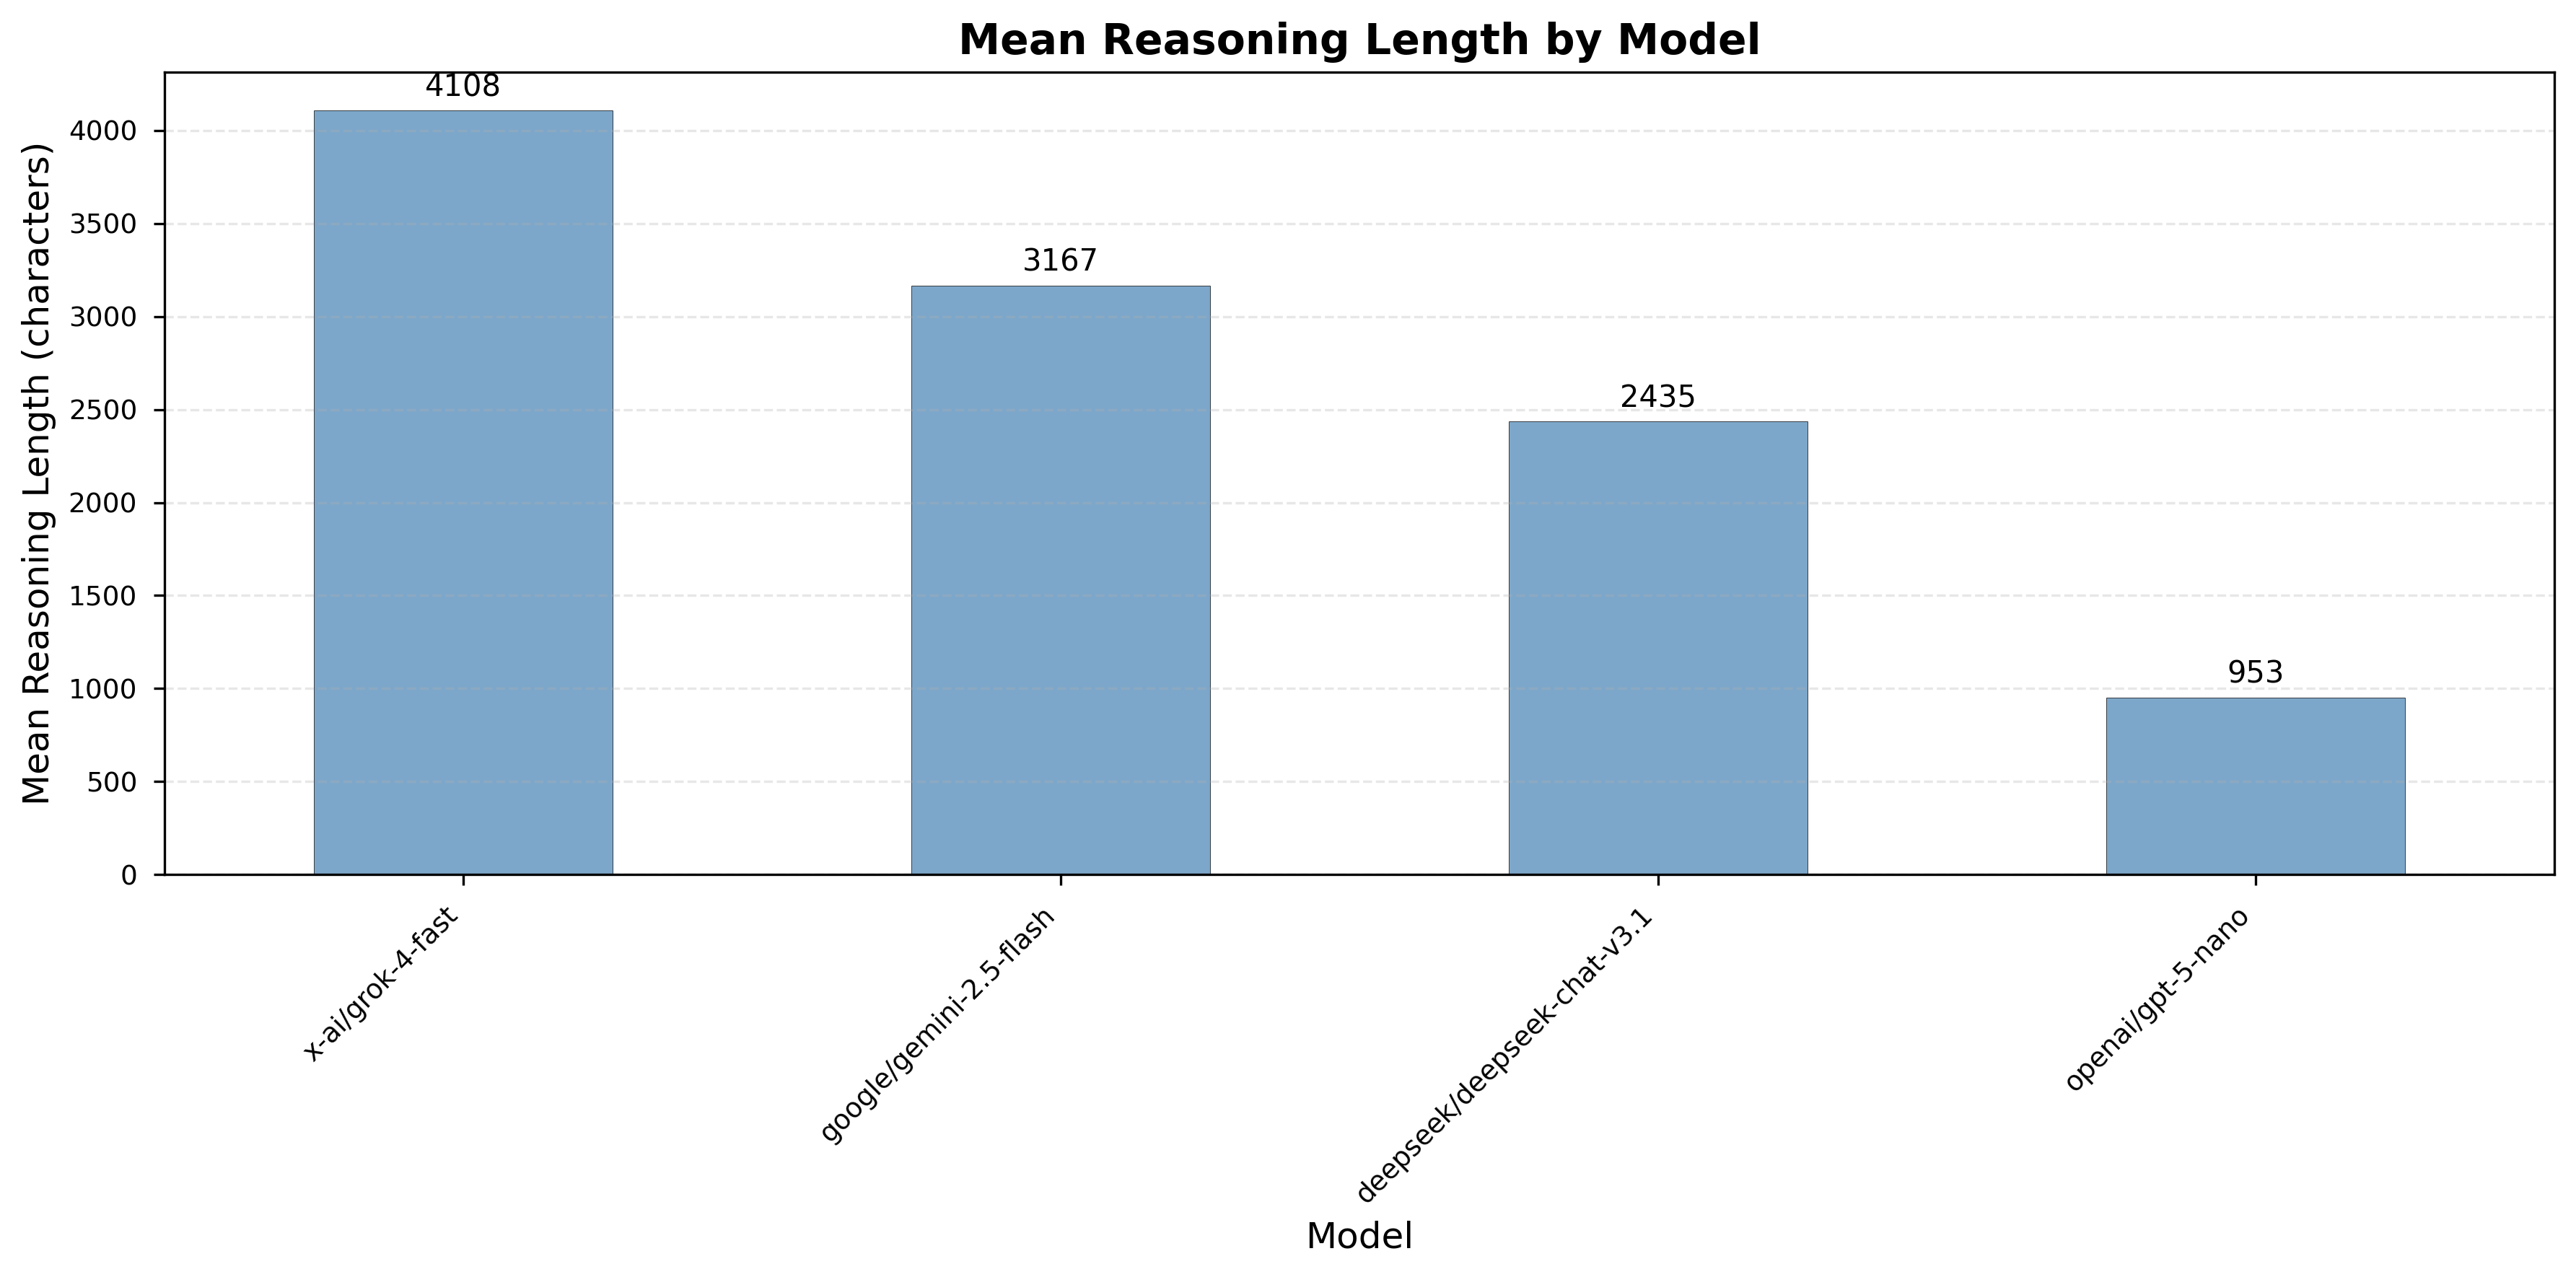

In [120]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate reasoning length
df['reasoning_length'] = df['reasoning'].astype(str).str.len()

# Calculate mean reasoning length by model
mean_reasoning = df.groupby('model')['reasoning_length'].mean().sort_values(ascending=False)

# Create bar plot
plt.figure(figsize=(12, 6))
ax = mean_reasoning.plot(kind='bar', color='steelblue', edgecolor='black', alpha=0.7)

plt.title('Mean Reasoning Length by Model', fontsize=14, fontweight='bold')
plt.xlabel('Model', fontsize=12)
plt.ylabel('Mean Reasoning Length (characters)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()

# Add value labels on bars
for i, v in enumerate(mean_reasoning):
    ax.text(i, v + max(mean_reasoning)*0.01, f'{v:.0f}', 
            ha='center', va='bottom', fontsize=10)

plt.show()


### Function Definition

In [121]:
def plot_categorical_frequency(df, x_col, hue_col=None, figsize=(10, 6), 
                                 rotation=45, title=None, xlabel=None, 
                                 ylabel='Count', palette='colorblind',
                                 show_values=True, percentage=False,
                                 sort_by='x', ax=None):
    """
    Create a bar graph showing frequency counts of categorical variables with optional hue stratification.

    Parameters:
    -----------
    df : pandas.DataFrame
        Input dataframe
    x_col : str
        Column name for x-axis (categorical variable)
    hue_col : str, optional
        Column name for hue/stratification (categorical variable)
    figsize : tuple, default=(10, 6)
        Figure size (width, height)
    rotation : int, default=45
        Rotation angle for x-axis labels
    title : str, optional
        Plot title. If None, auto-generated
    xlabel : str, optional
        X-axis label. If None, uses x_col name
    ylabel : str, default='Count'
        Y-axis label
    palette : str or list, default='colorblind'
        Color palette for bars
    show_values : bool, default=True
        Whether to show count values on top of bars
    percentage : bool, default=False
        If True, show percentages instead of raw counts
    sort_by : str, default='x'
        How to sort bars: 'x' (by x categories), 'count' (by frequency), 
        'hue' (by hue categories), or None
    ax : matplotlib.axes.Axes, optional
        Existing axes to plot on. If None, creates new figure

    Returns:
    --------
    fig, ax : matplotlib figure and axes objects

    Examples:
    ---------
    >>> # Simple frequency plot
    >>> plot_categorical_frequency(df, x_col='category')

    >>> # With hue stratification
    >>> plot_categorical_frequency(df, x_col='category', hue_col='subcategory')

    >>> # Show percentages sorted by frequency
    >>> plot_categorical_frequency(df, x_col='category', hue_col='group', 
    ...                             percentage=True, sort_by='count')

    >>> # Multiple subplots
    >>> fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    >>> plot_categorical_frequency(df, x_col='cat1', ax=axes[0])
    >>> plot_categorical_frequency(df, x_col='cat2', ax=axes[1])
    """

    # Create figure if ax not provided
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.get_figure()

    # Prepare data
    if hue_col is not None:
        # Count frequencies with hue
        counts = df.groupby([x_col, hue_col]).size().reset_index(name='count')

        # Sort if requested
        if sort_by == 'count':
            # Sort by total count per x category
            x_order = df[x_col].value_counts().index.tolist()
            counts[x_col] = pd.Categorical(counts[x_col], categories=x_order, ordered=True)
            counts = counts.sort_values([x_col, hue_col])
        elif sort_by == 'hue':
            counts = counts.sort_values([hue_col, x_col])
        elif sort_by == 'x':
            counts = counts.sort_values([x_col, hue_col])

        # Calculate percentages if requested
        if percentage:
            total = counts.groupby(x_col)['count'].transform('sum')
            counts['percentage'] = (counts['count'] / total * 100).round(1)
            value_col = 'percentage'
            if ylabel == 'Count':
                ylabel = 'Percentage (%)'
        else:
            value_col = 'count'

        # Create grouped bar plot
        x_cats = counts[x_col].unique()
        hue_cats = counts[hue_col].unique()
        n_hues = len(hue_cats)

        # Set up bar positions
        x_pos = np.arange(len(x_cats))
        width = 0.8 / n_hues

        # Get colors
        if isinstance(palette, str):
            colors = sns.color_palette(palette, n_colors=n_hues)
        else:
            colors = palette

        # Plot bars for each hue
        for i, hue_val in enumerate(hue_cats):
            hue_data = counts[counts[hue_col] == hue_val]
            # Align with x_cats order
            values = []
            for x_cat in x_cats:
                val = hue_data[hue_data[x_col] == x_cat][value_col].values
                values.append(val[0] if len(val) > 0 else 0)

            offset = width * (i - n_hues/2 + 0.5)
            bars = ax.bar(x_pos + offset, values, width, label=hue_val, 
                         color=colors[i], alpha=0.8, edgecolor='black', linewidth=0.5)

            # Add value labels on bars
            if show_values:
                for j, (bar, val) in enumerate(zip(bars, values)):
                    if val > 0:
                        label = f'{val:.1f}%' if percentage else f'{int(val)}'
                        height = bar.get_height()
                        ax.text(bar.get_x() + bar.get_width()/2., height,
                               label, ha='center', va='bottom', fontsize=8)

        ax.set_xticks(x_pos)
        ax.set_xticklabels(x_cats, rotation=rotation, ha='right')
        ax.legend(title=hue_col.replace('_', ' ').title(), 
                 bbox_to_anchor=(1.05, 1), loc='upper left')

    else:
        # Simple frequency count without hue
        counts = df[x_col].value_counts()

        # Sort if requested
        if sort_by == 'count':
            counts = counts.sort_values(ascending=False)
        elif sort_by == 'x':
            counts = counts.sort_index()

        # Calculate percentages if requested
        if percentage:
            total = counts.sum()
            values = (counts / total * 100).round(1)
            if ylabel == 'Count':
                ylabel = 'Percentage (%)'
        else:
            values = counts

        # Plot bars
        bars = ax.bar(range(len(values)), values.values, 
                     color=sns.color_palette(palette, n_colors=len(values)),
                     alpha=0.8, edgecolor='black', linewidth=0.5)

        # Add value labels
        if show_values:
            for bar, val in zip(bars, values.values):
                label = f'{val:.1f}%' if percentage else f'{int(val)}'
                height = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2., height,
                       label, ha='center', va='bottom', fontsize=9)

        ax.set_xticks(range(len(values)))
        ax.set_xticklabels(values.index, rotation=rotation, ha='right')

    # Labels and title
    ax.set_xlabel(xlabel if xlabel else x_col.replace('_', ' ').title(), fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)

    if title is None:
        if hue_col:
            title = f'Frequency Distribution of {x_col.replace("_", " ").title()} by {hue_col.replace("_", " ").title()}'
        else:
            title = f'Frequency Distribution of {x_col.replace("_", " ").title()}'
    ax.set_title(title, fontsize=12, fontweight='bold')

    # Grid and styling
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()

    return fig, ax

### Function Call

In [122]:
columns_of_interest = ['mentions_hospital_capacity', 'computed_hospital_demand', 'compares_demand_to_capacity', 
    'calculated_hospital_shortfall', 'economic_impact_depth', 'mentions_business_closures', 
    'compares_infection_rates_between_options', 'argues_closures_not_worth_it_given_infections', 'mentions_user_preference']

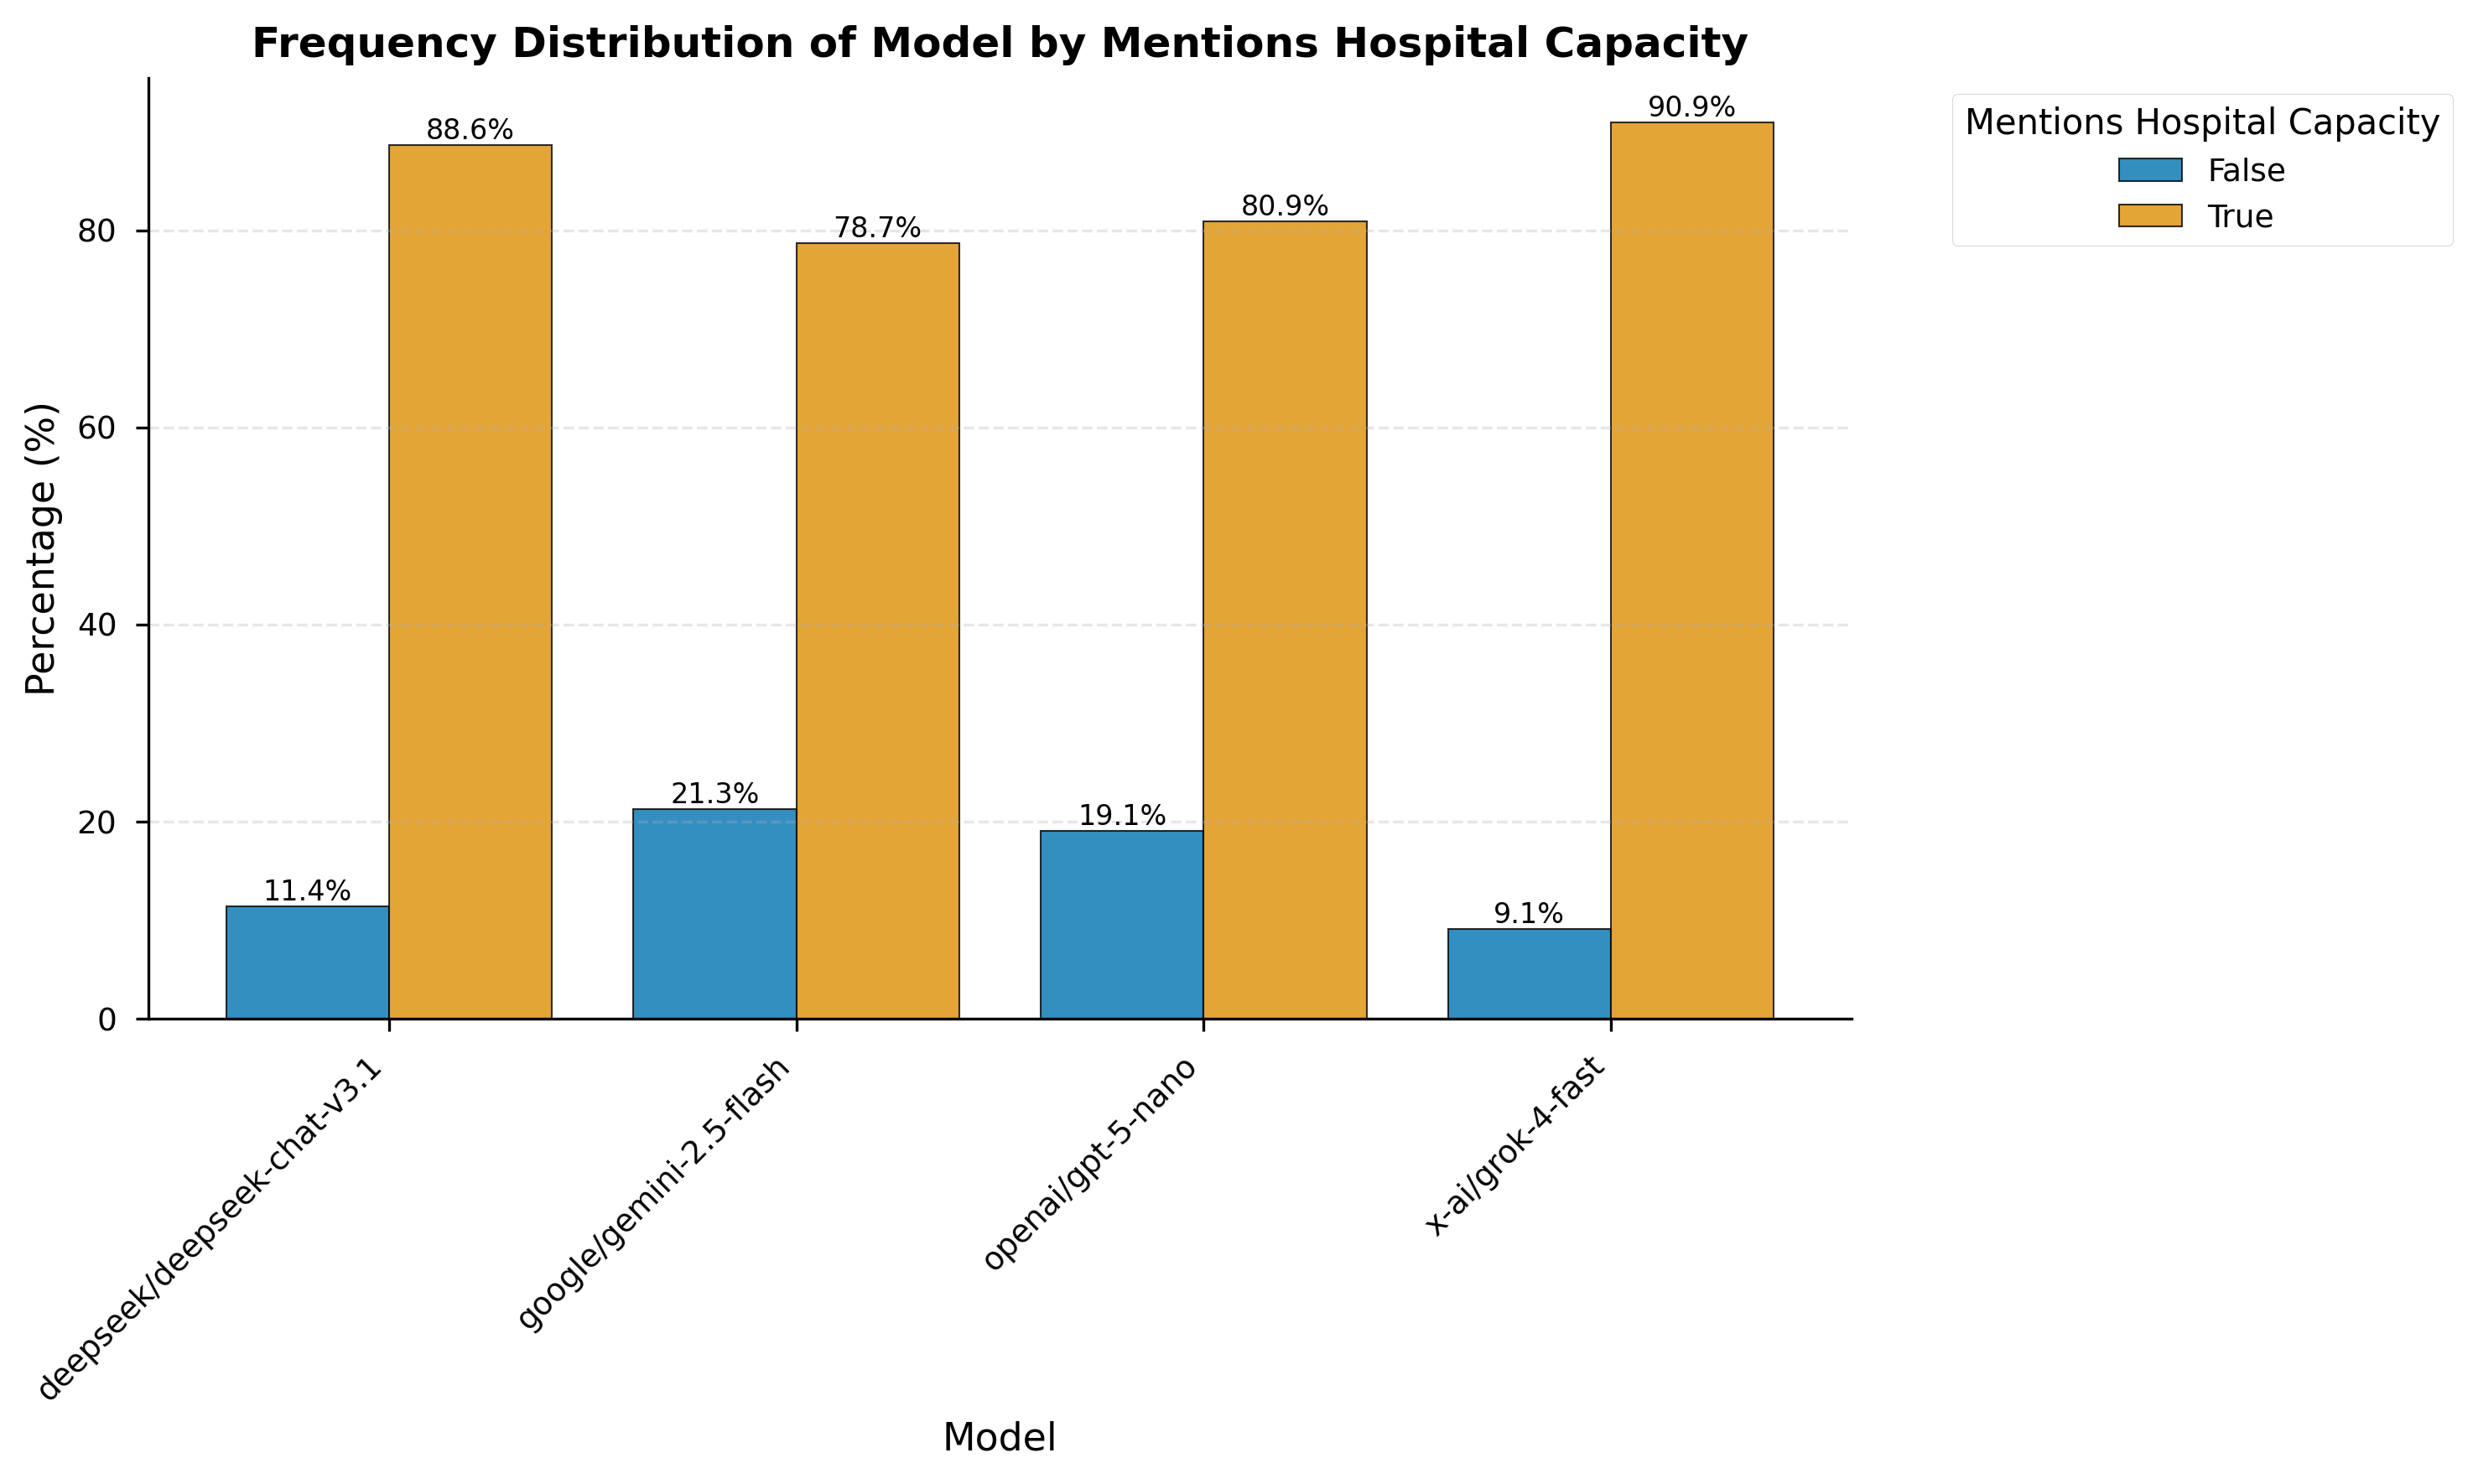

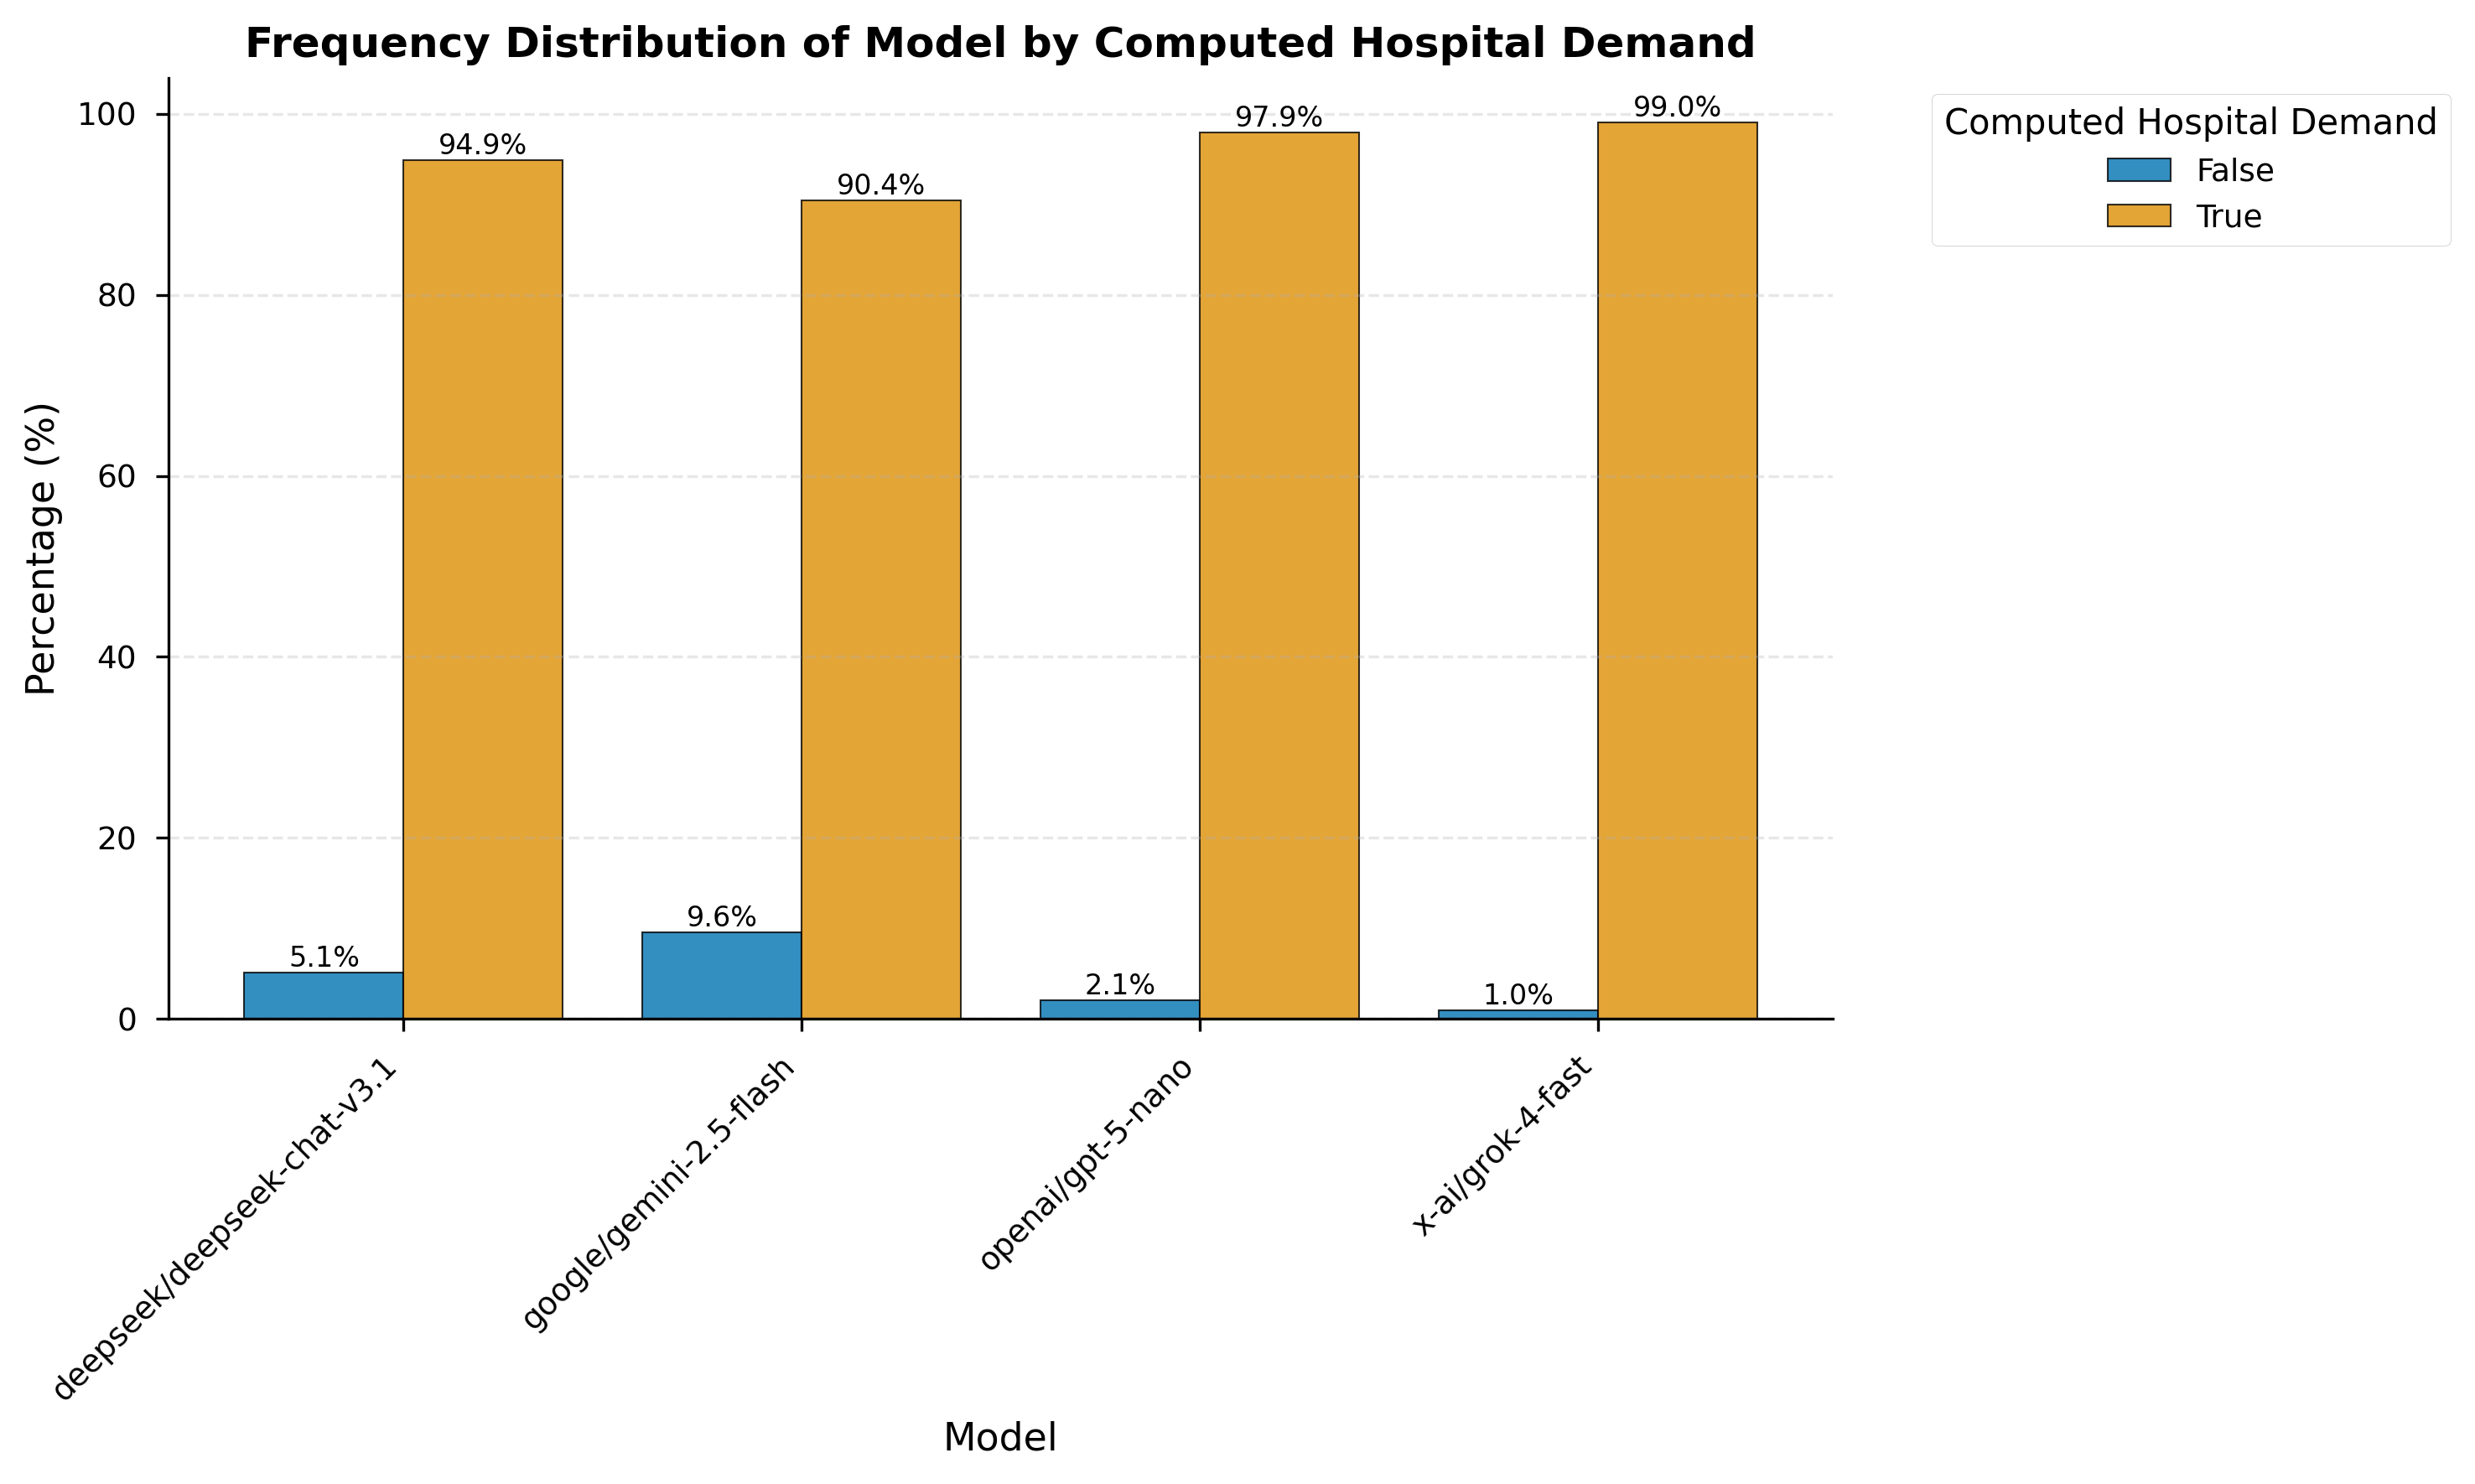

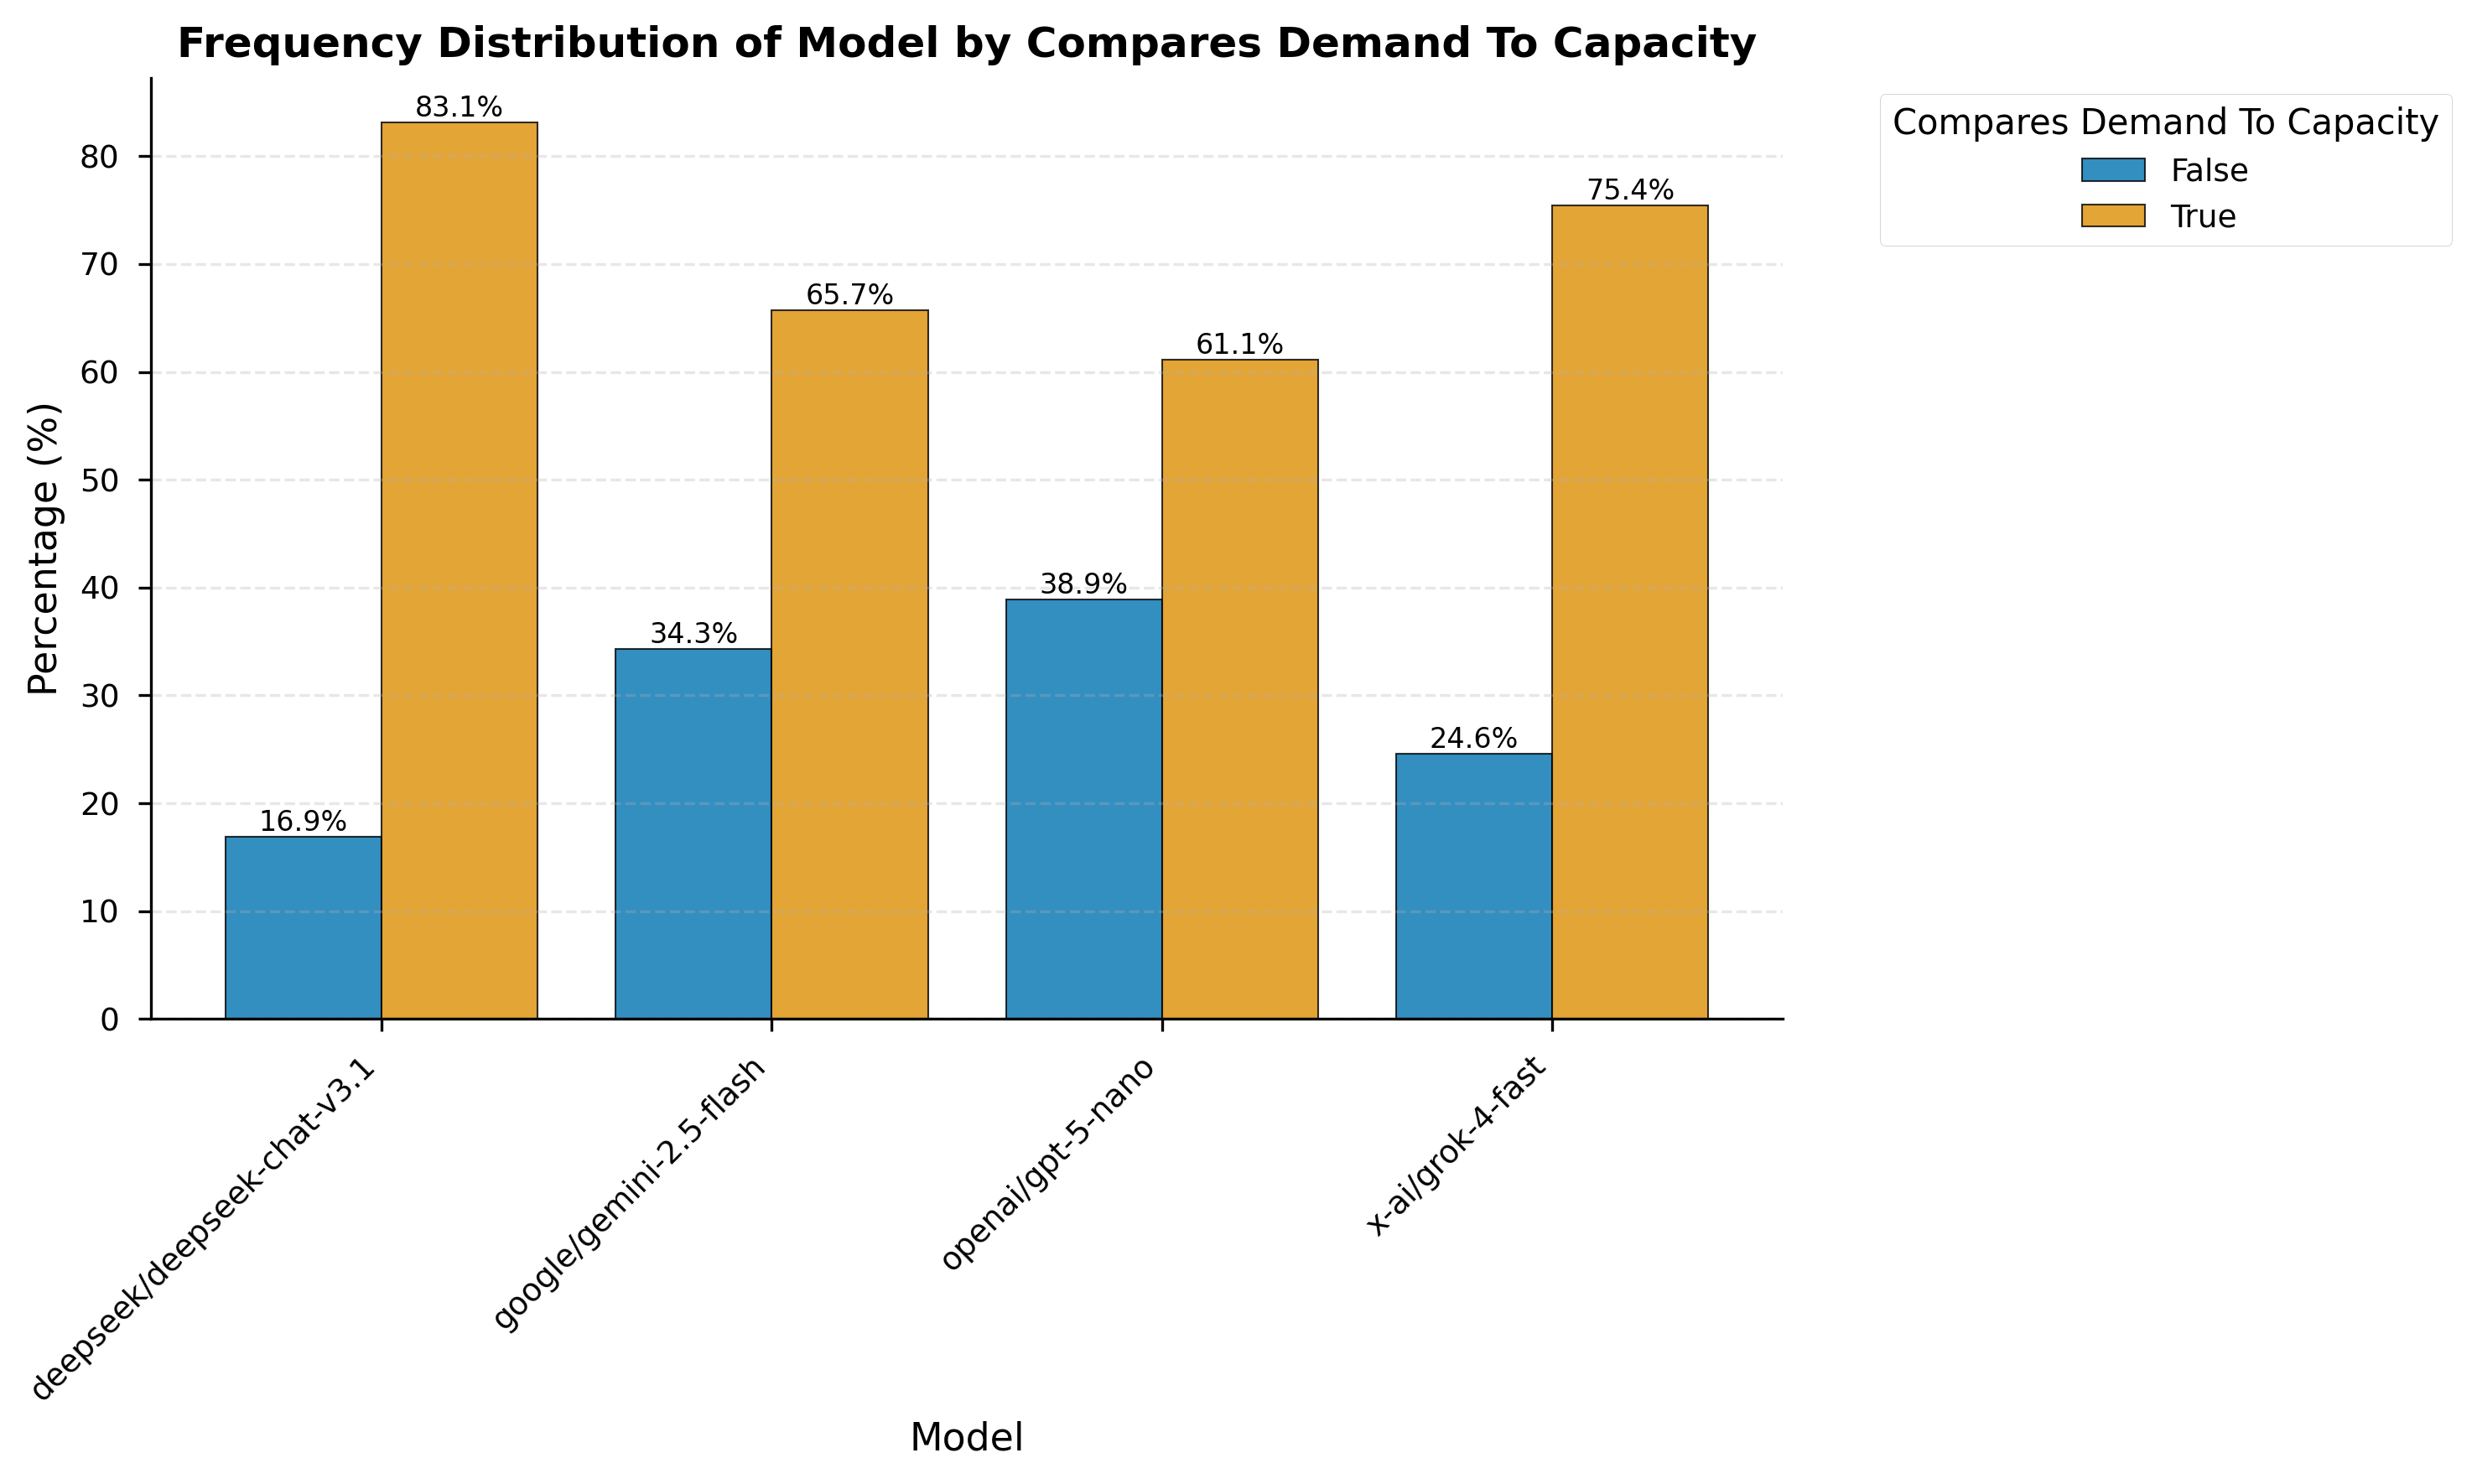

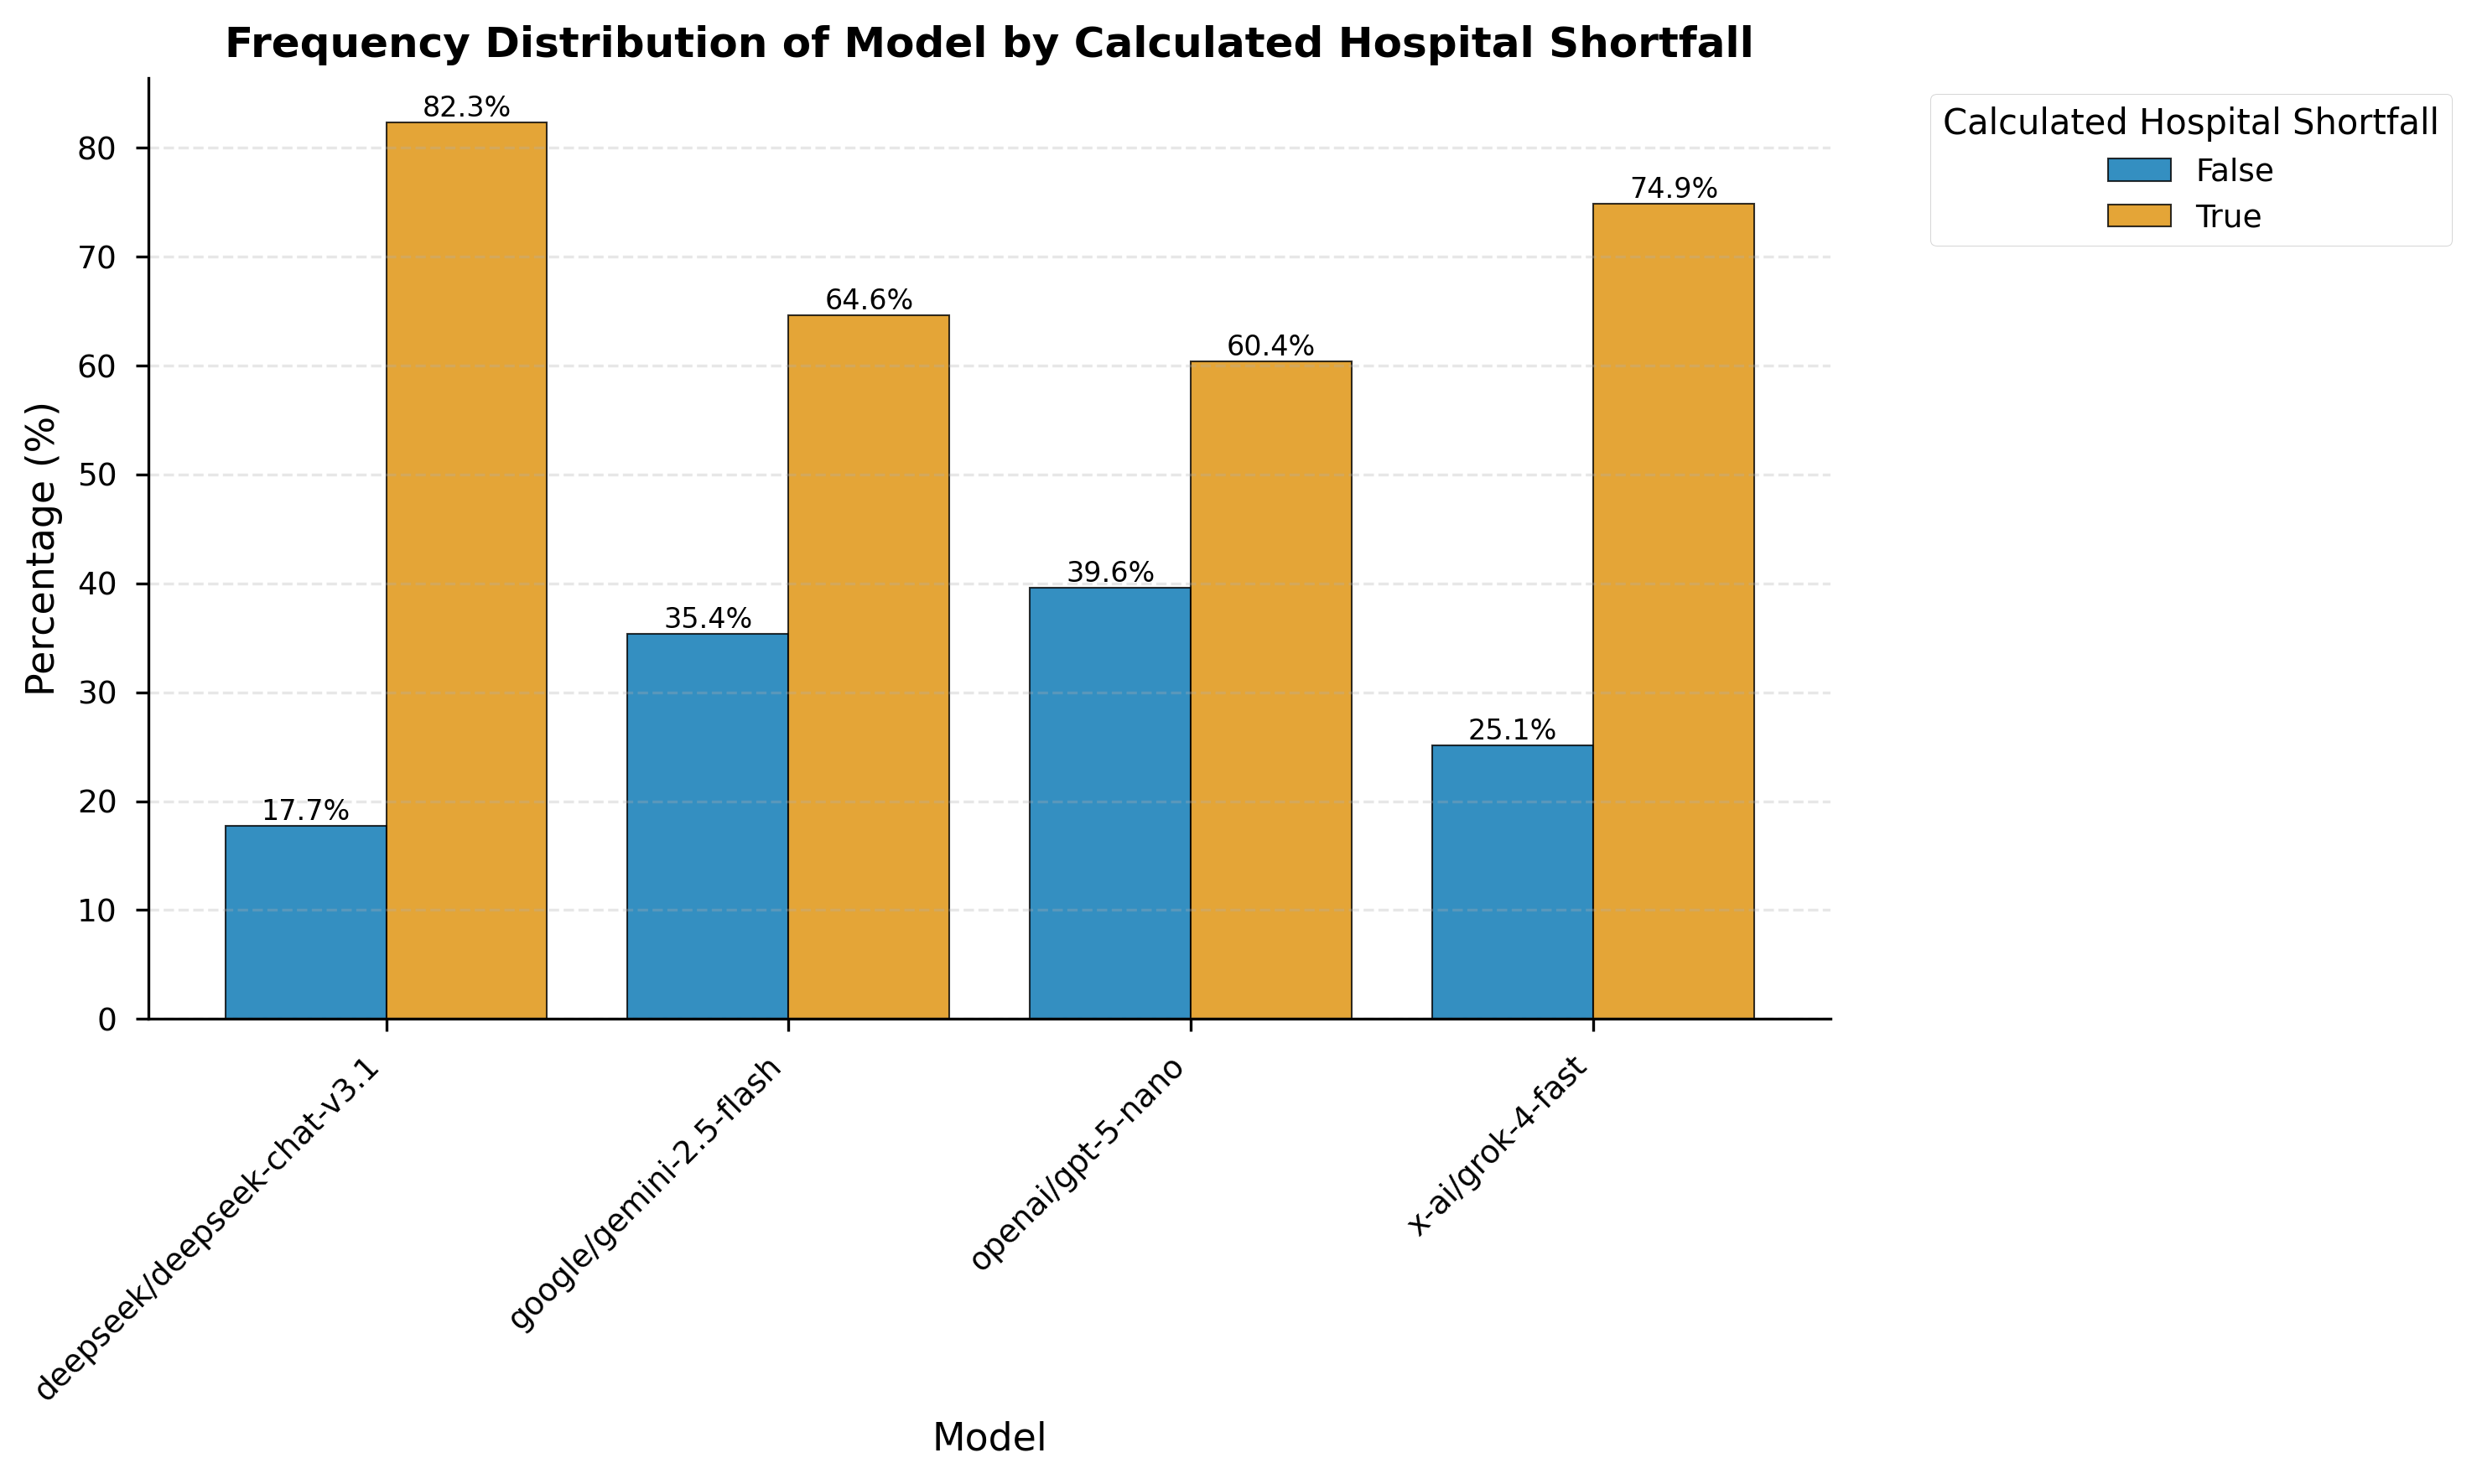

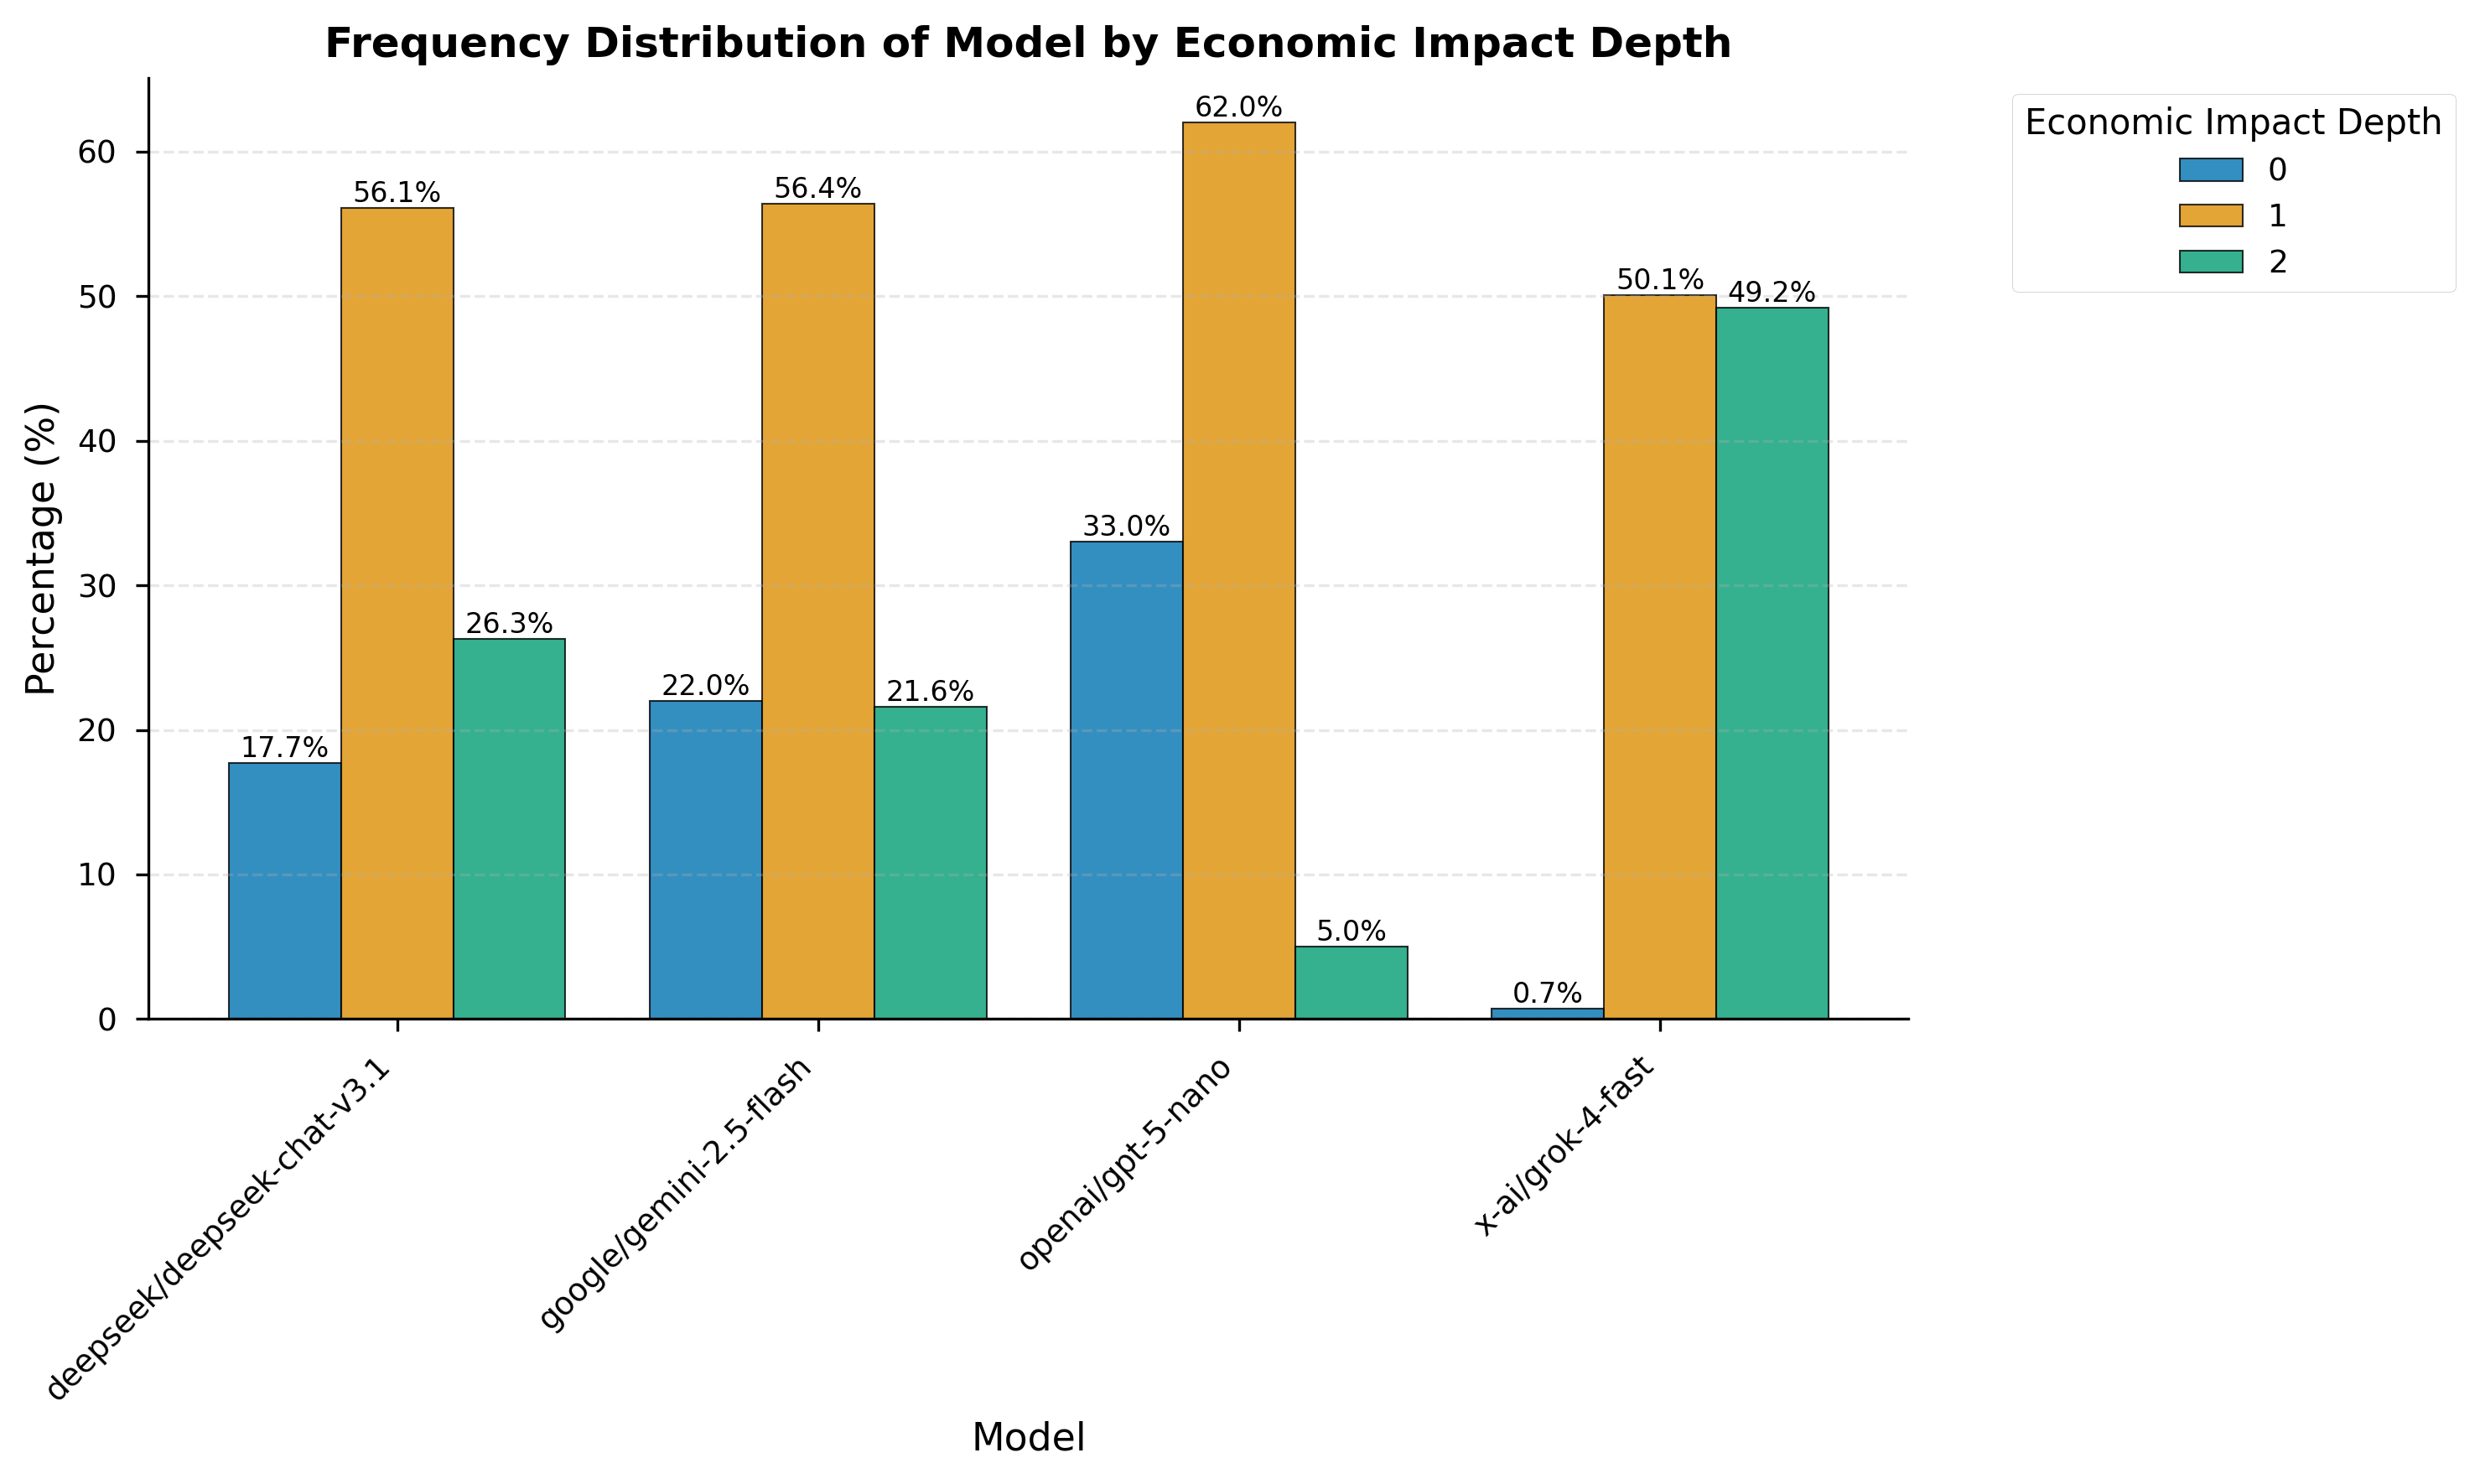

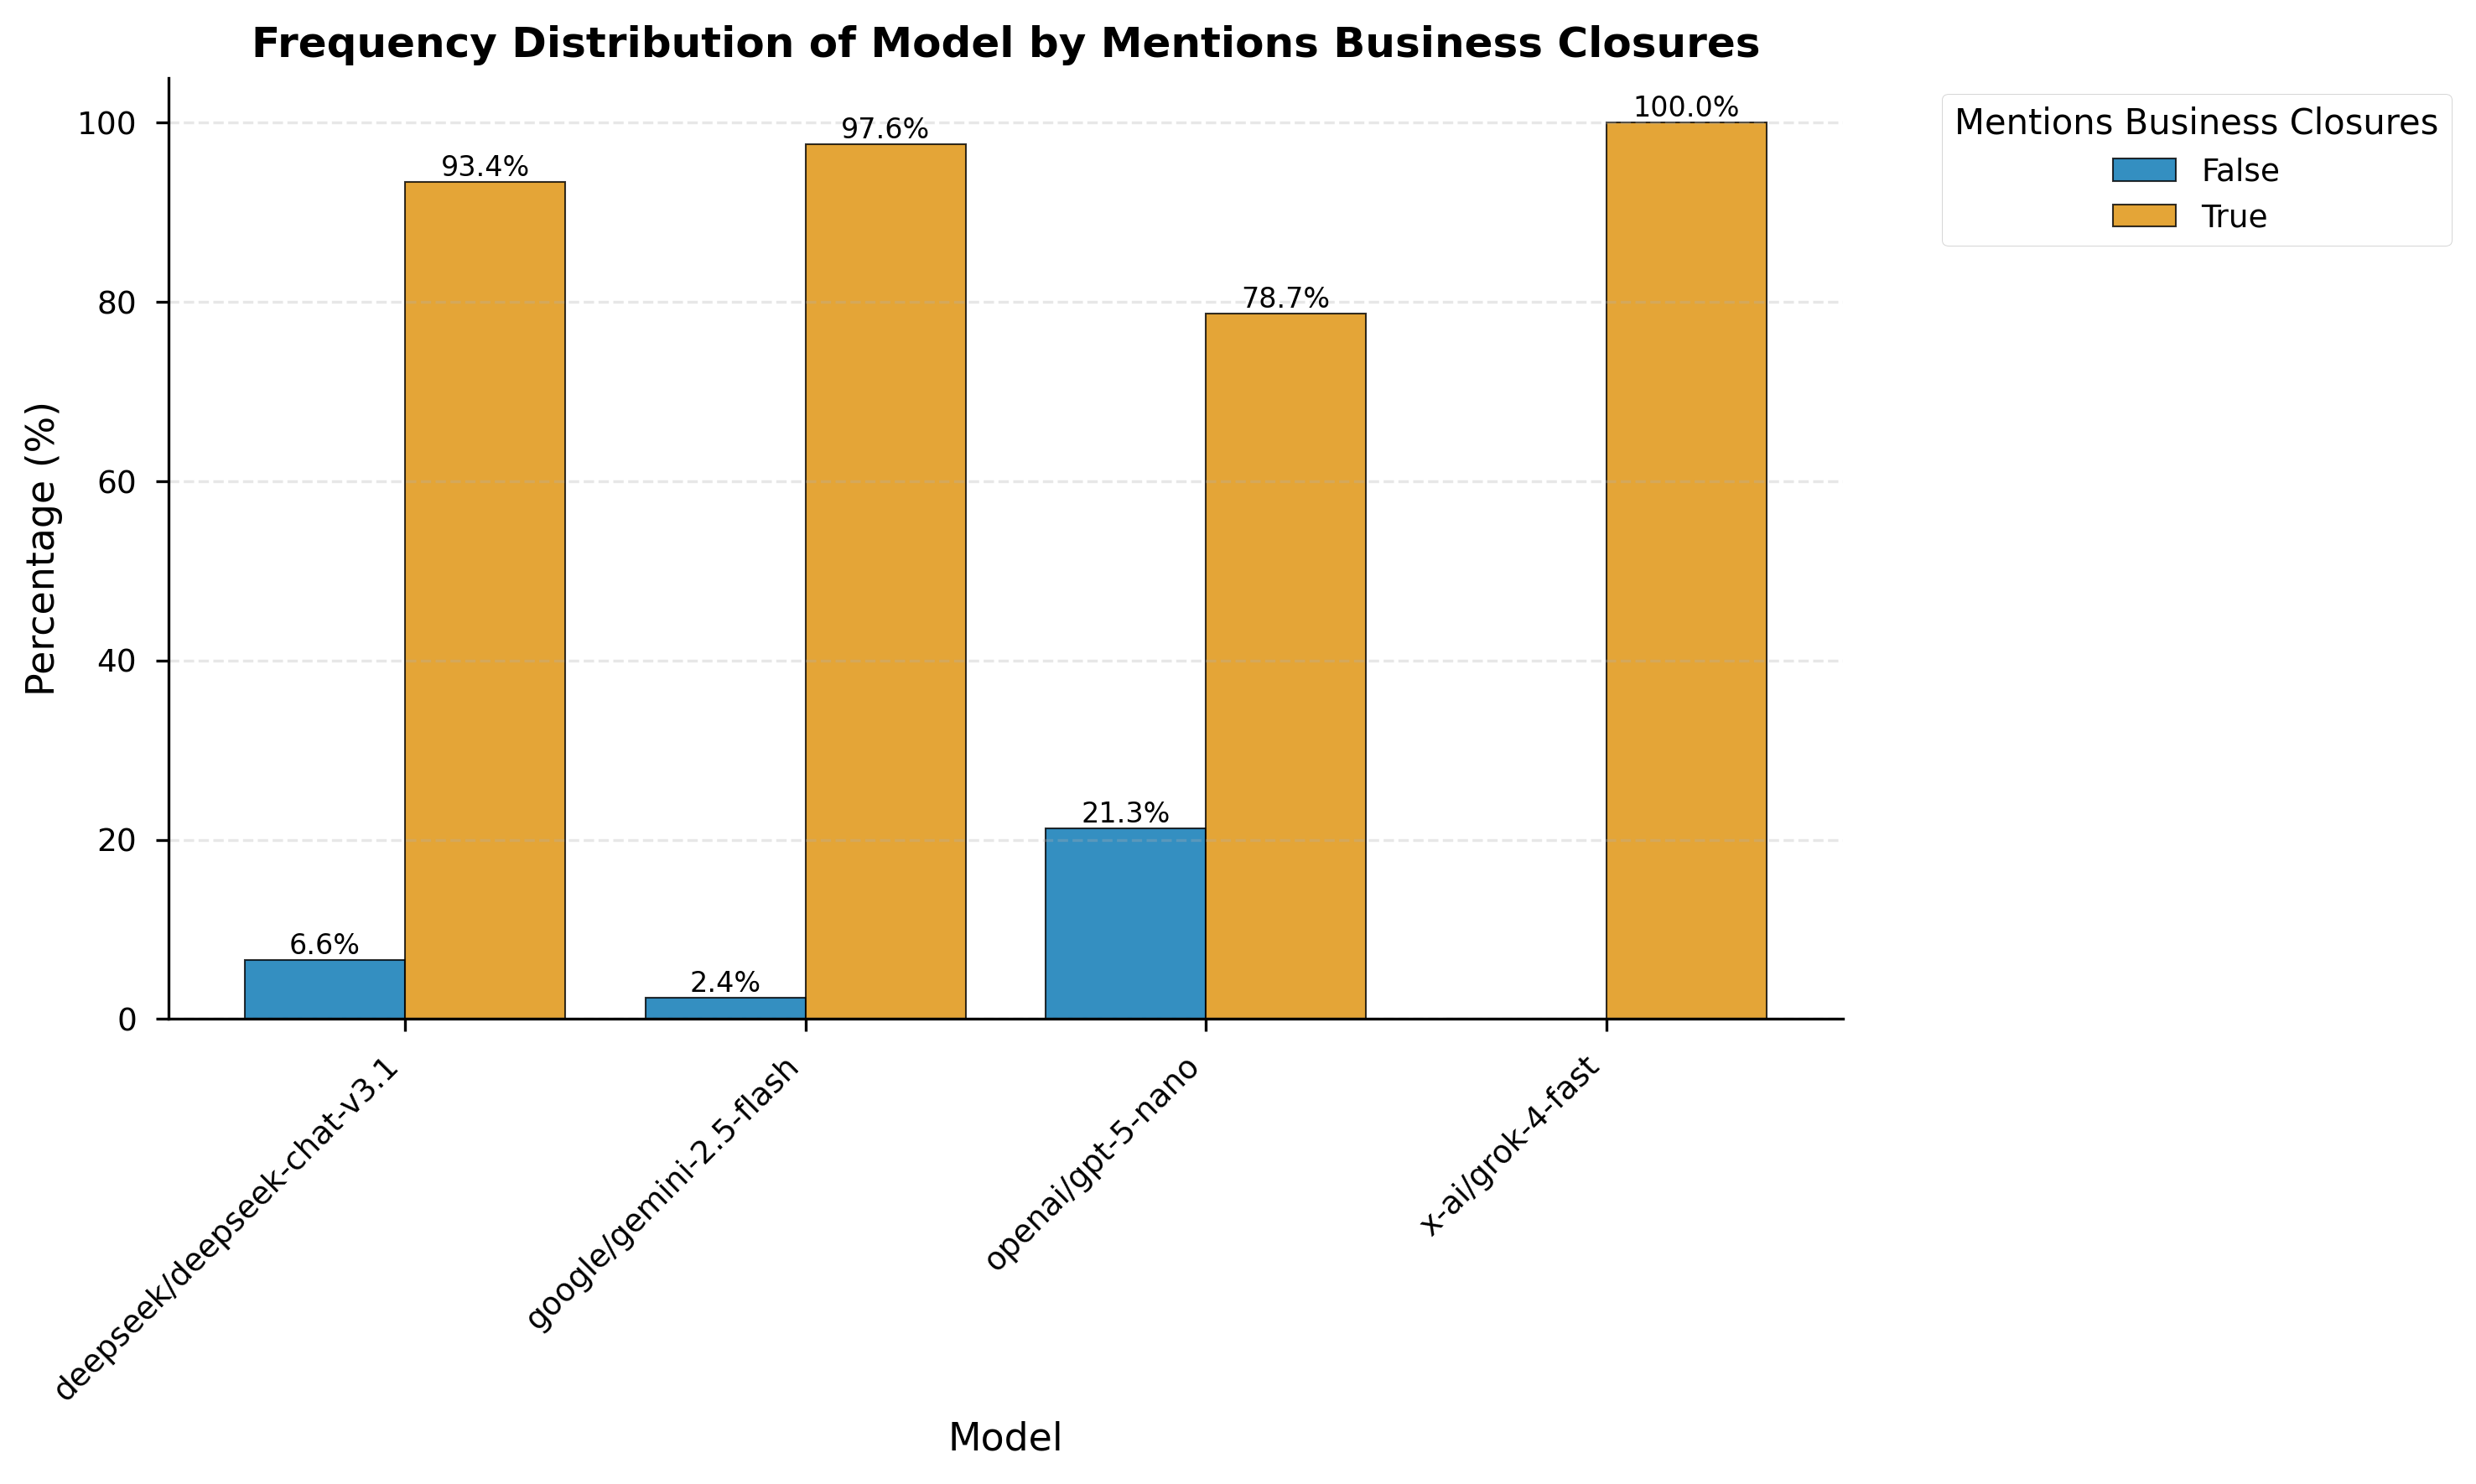

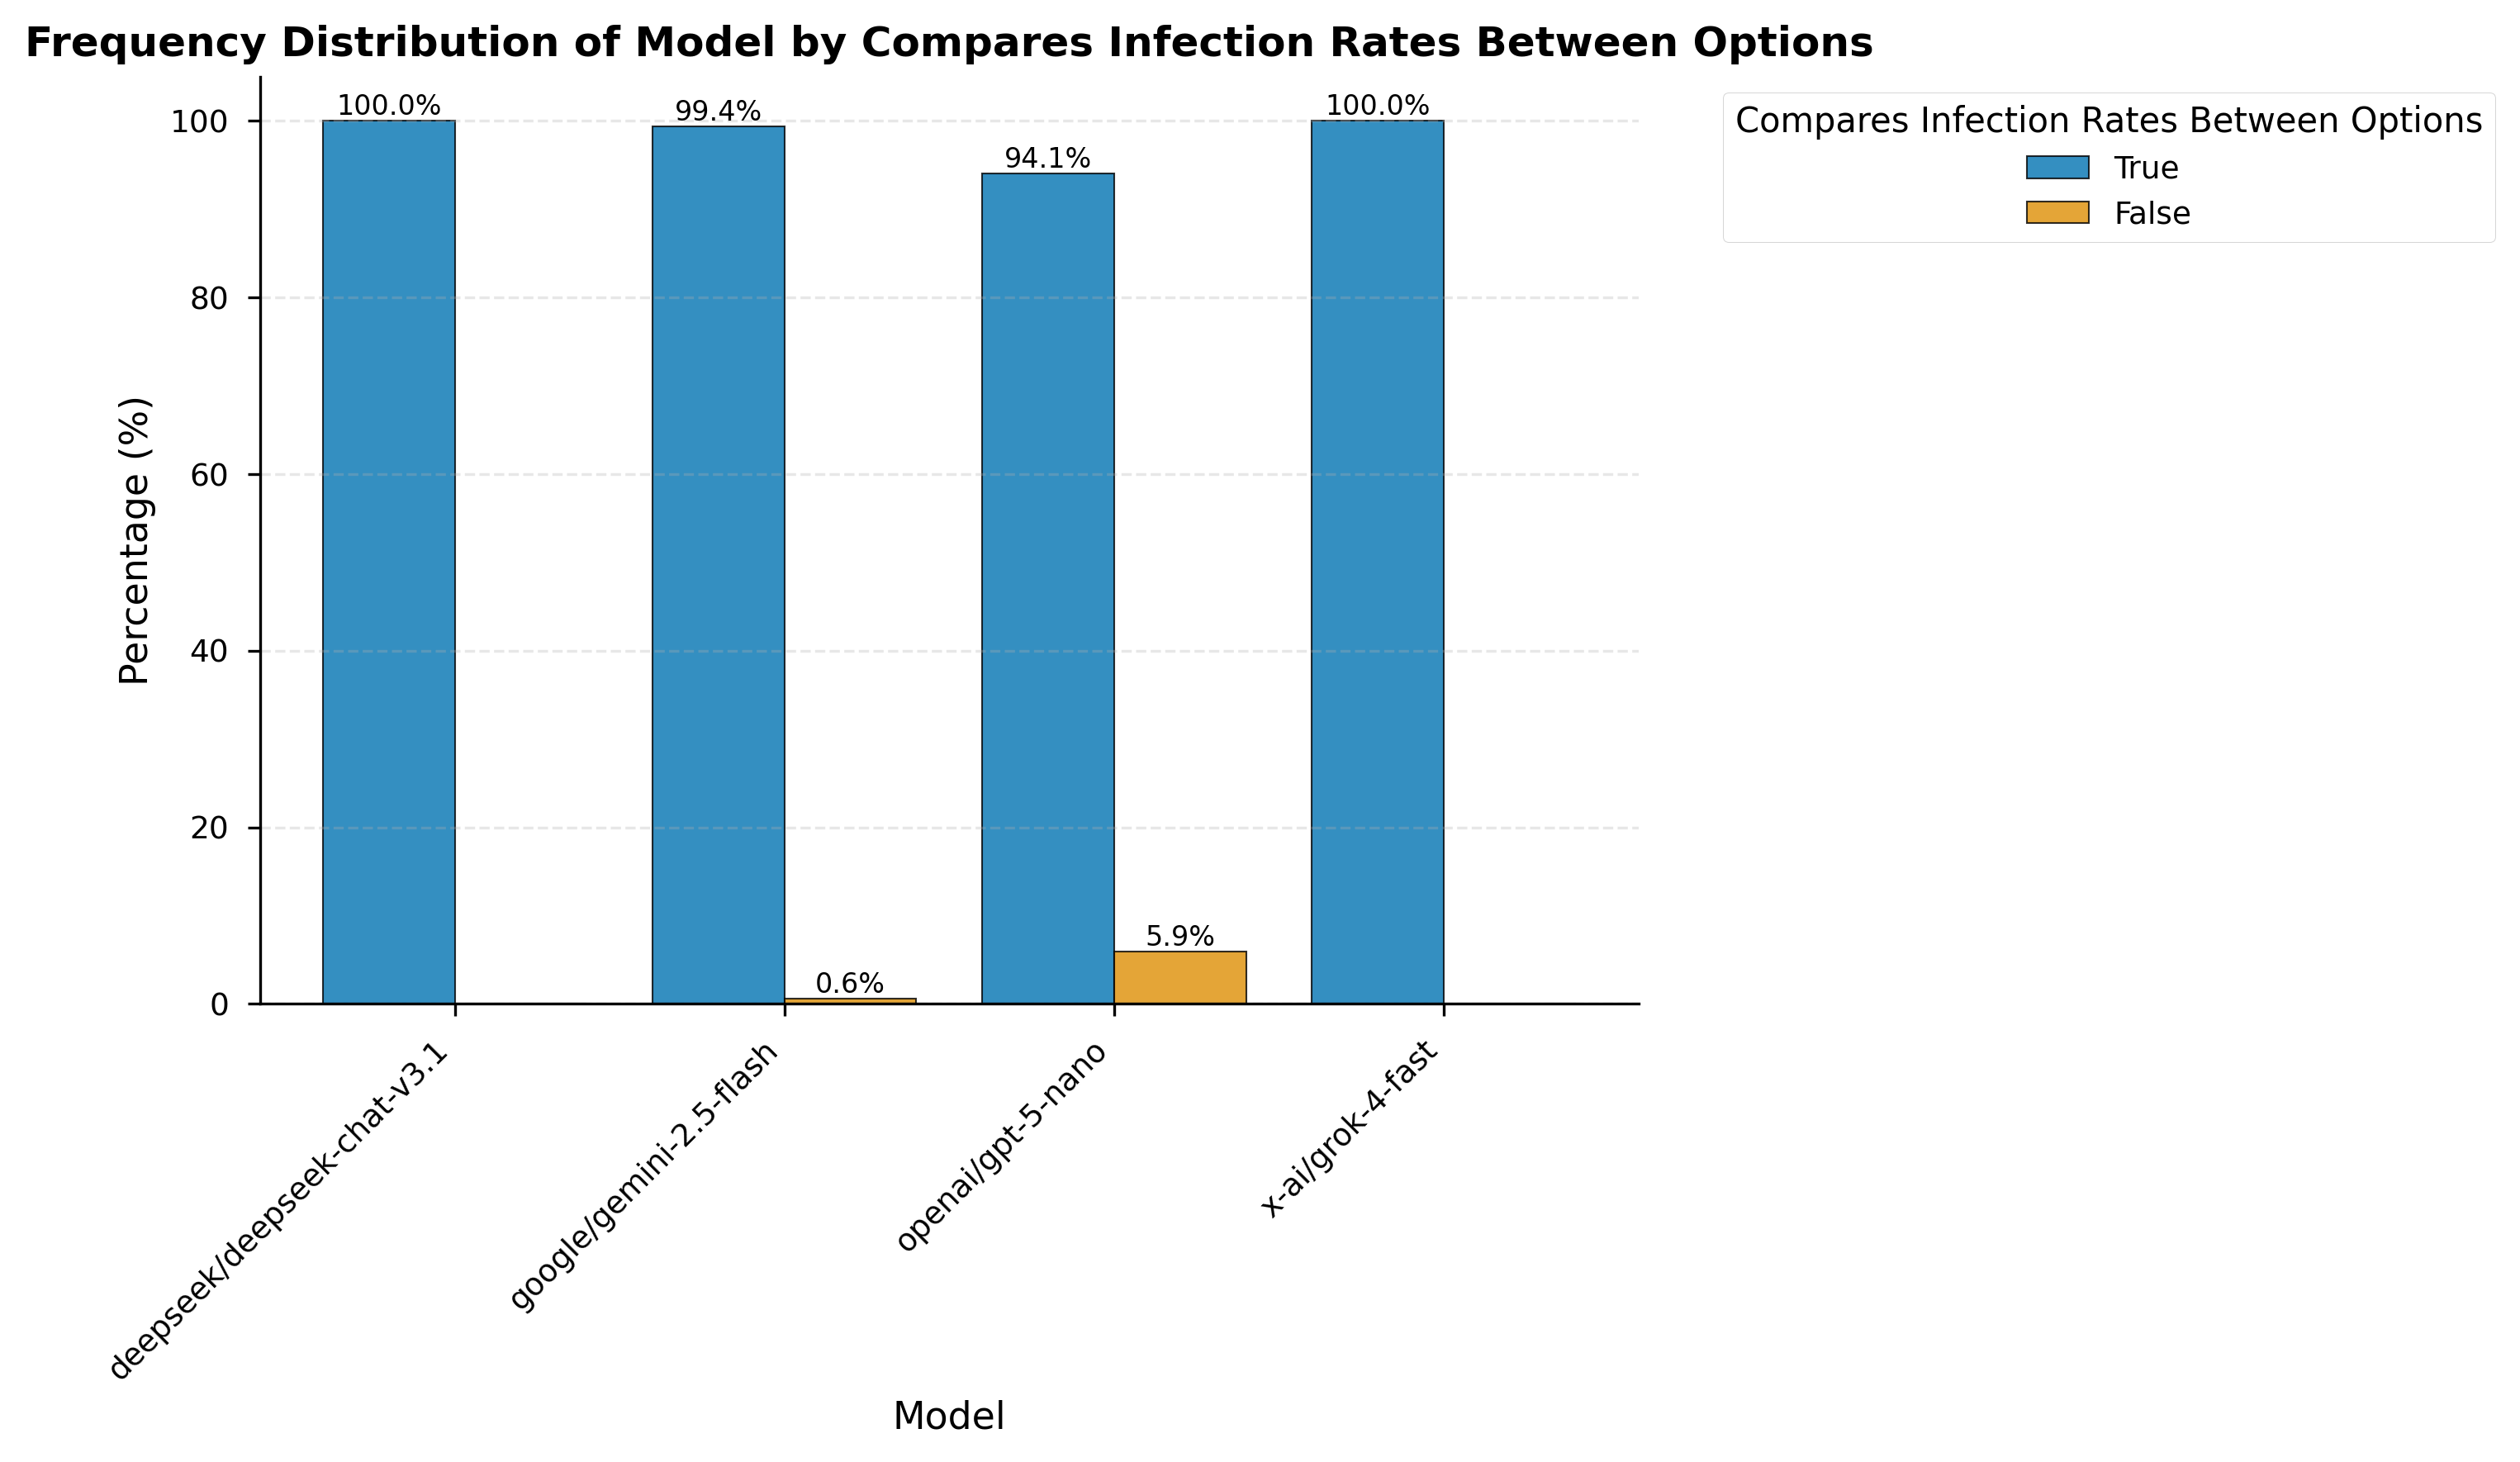

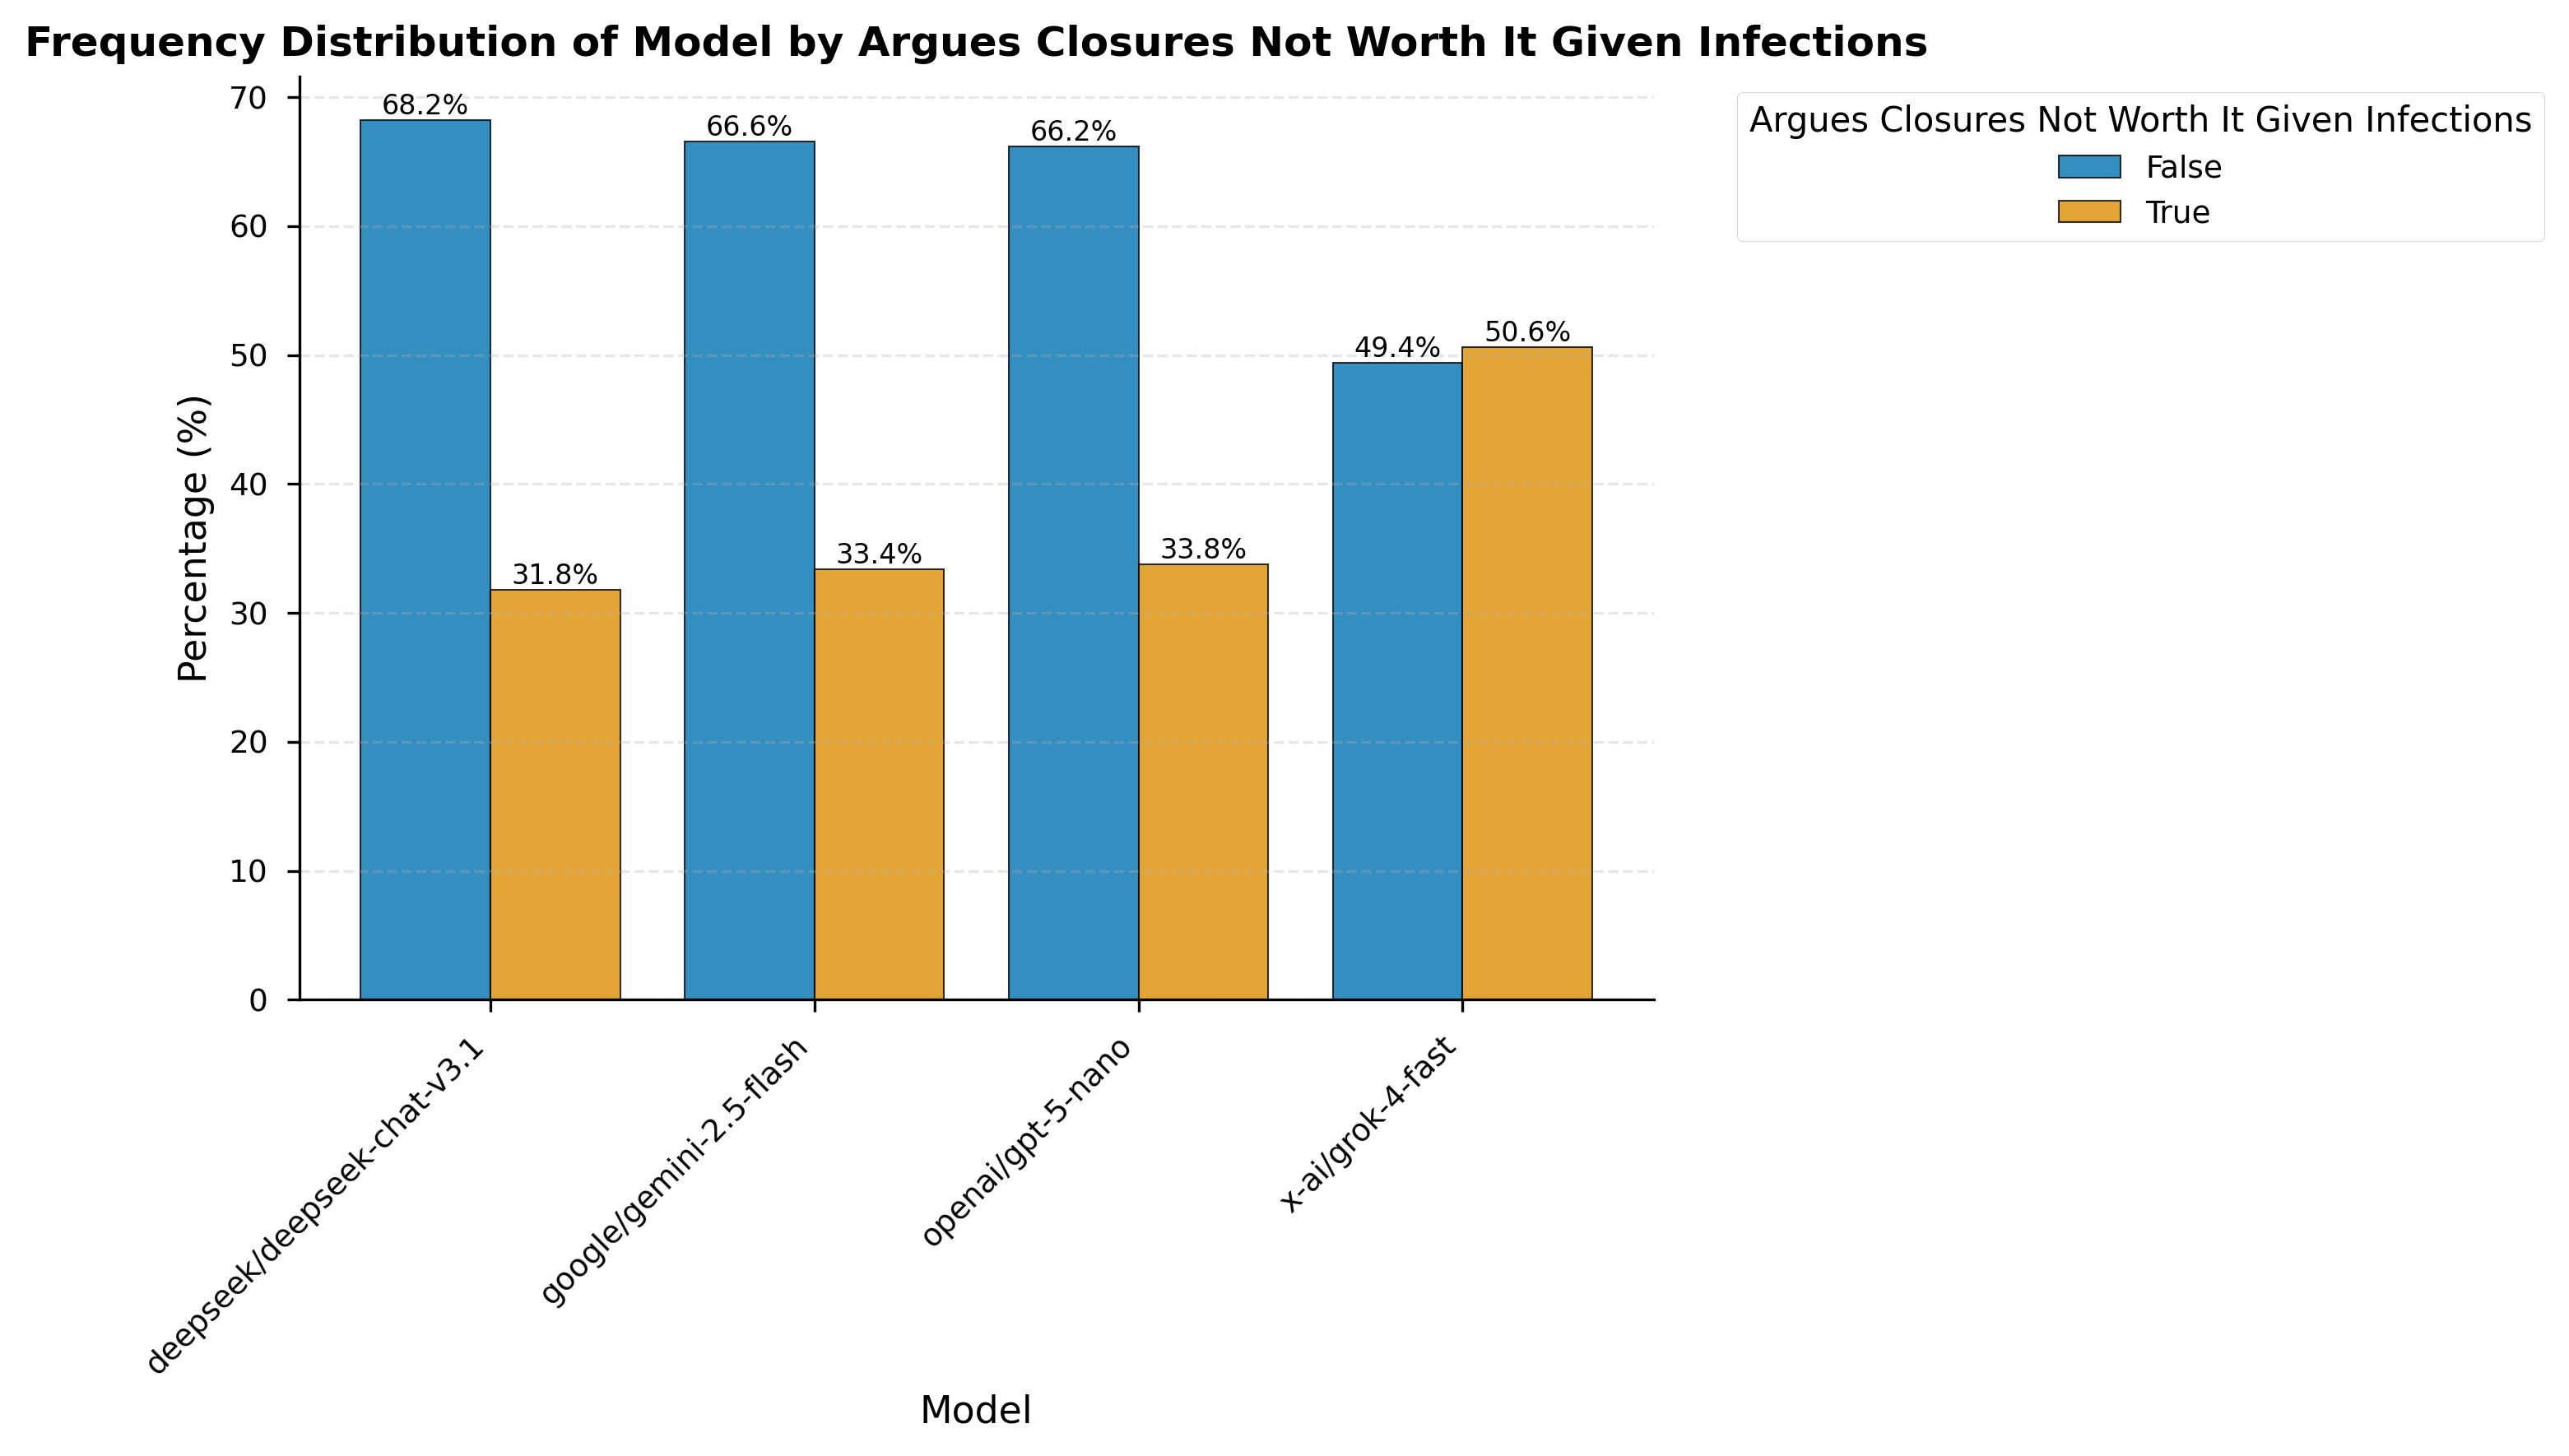

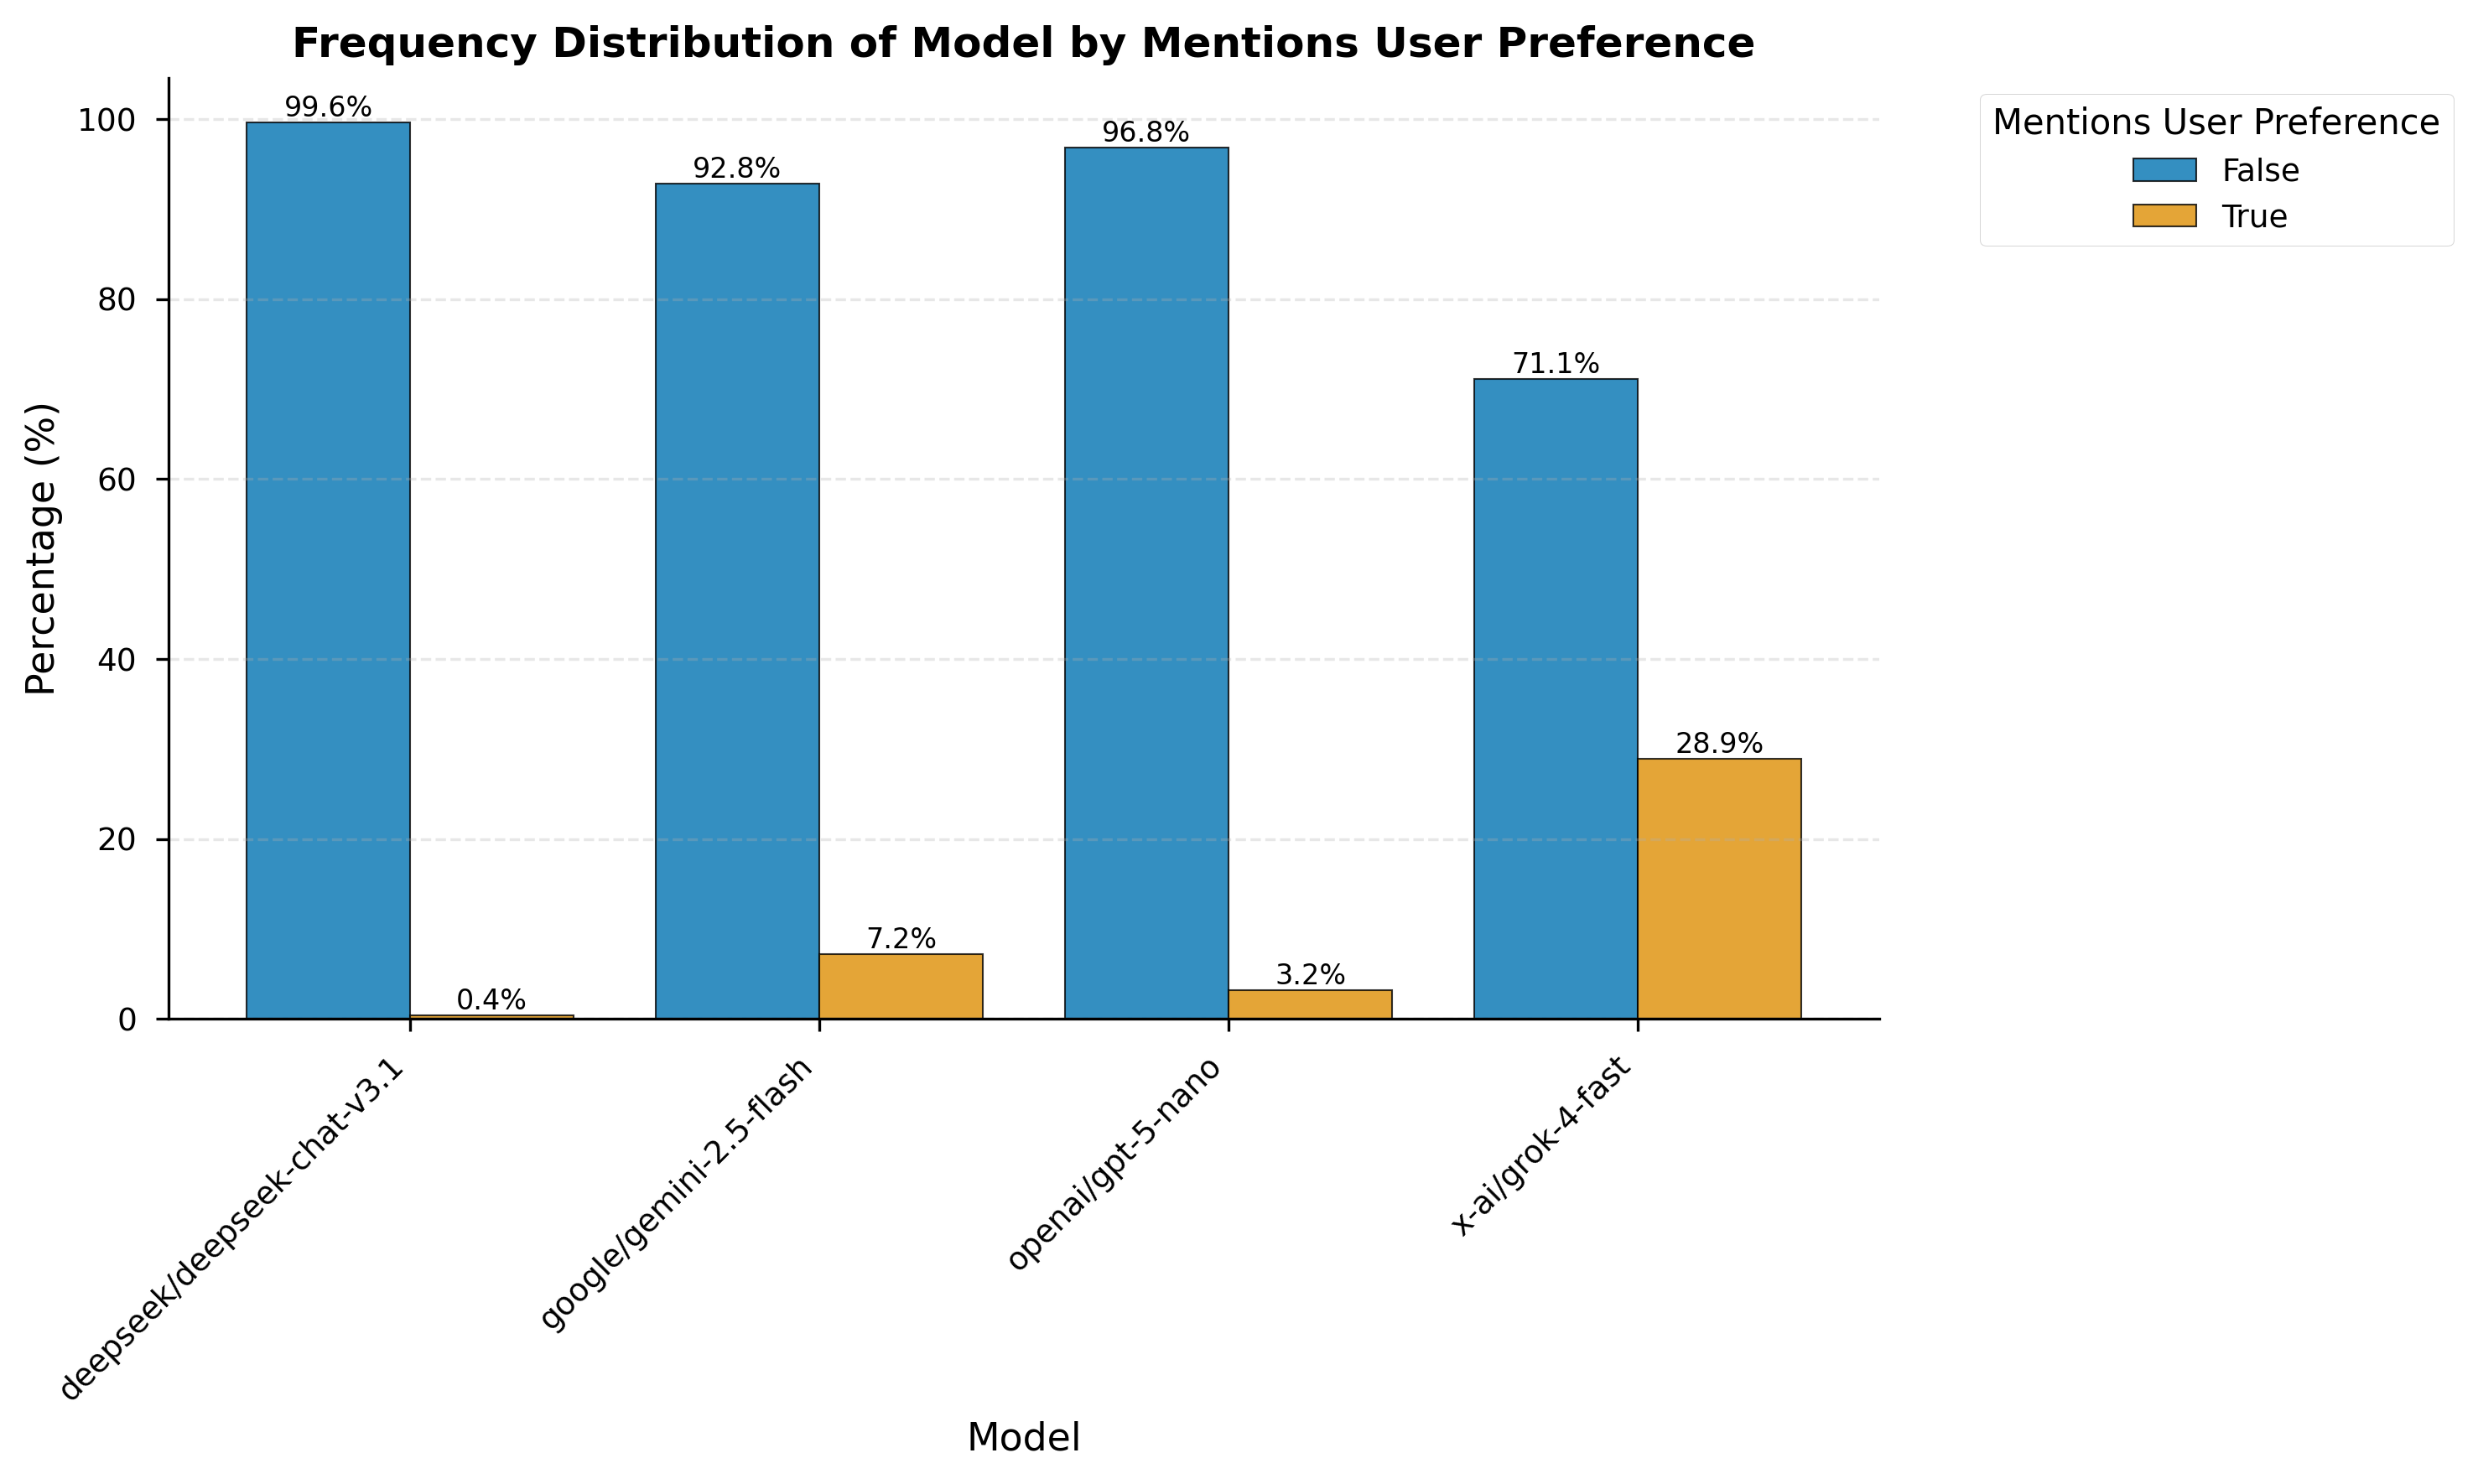

In [123]:
for col in columns_of_interest:
    plot_categorical_frequency(df, 'model', col, percentage=True)

## 3. Irrational Choice Analysis